In [1]:
# ============================================================
# 05_LandUse_Soil_CN.ipynb | Cell 1: setup, subcatchments, helpers
# ============================================================
import importlib, os, requests
import numpy as np
import matplotlib.colors as mcolors
from scipy import ndimage
from rasterio.io import MemoryFile
from rasterio.warp import reproject, Resampling
import utils
importlib.reload(utils)
from utils import *

P = get_paths()
ws = WatershedGrid(P.RAS / "watershed_mask.tif", P.VEC / "watershed_boundary.gpkg",
                   P.VEC / "outlet_snapped.shp")
H, W = ws.mask.shape
print(ws)


def read_grid(path):
    with rasterio.open(path) as s:
        a = s.read(1).astype("float32"); nd = s.nodata
    if nd is not None:
        a[a == nd] = np.nan
    return a


# ---------- subcatchments from notebook 04 ----------
sub = np.nan_to_num(read_grid(P.RAS / "subcatchments.tif"), nan=0).astype("int32")
assert sub.shape == (H, W), "subcatchments.tif is on a different grid - rerun notebooks 01-04 in order"
N_SUB = int(sub.max())
sub_info = pd.read_csv(P.TAB / "04_subcatchments.csv")
gsub = gpd.read_file(P.VEC / "subcatchments.gpkg")
assert len(sub_info) == N_SUB == len(gsub), "subcatchment files disagree - rerun notebook 04 Cell 5"
CELLS_SUB = np.bincount(sub.ravel(), minlength=N_SUB + 1)[1:]
A_SUB = CELLS_SUB * ws.cell_area_km2
print(f"Subcatchments: {N_SUB} | total {A_SUB.sum():,.1f} km2")


# ---------- helpers ----------
def counts_by_sub(a, ncls):
    """(N_SUB x ncls+1) cell counts per subcatchment for an integer class array (0 = none)."""
    v = sub > 0
    return np.bincount(sub[v] * (ncls + 1) + a[v].astype("int32"),
                       minlength=(N_SUB + 1) * (ncls + 1)).reshape(N_SUB + 1, ncls + 1)[1:]


def add_to_gsub(df, cols):
    for c in cols:
        gsub[c] = gsub["sub_id"].map(df.set_index("sub_id")[c])


def class_map(a, table, fname, title, label):
    """Categorical map of a code raster. Returns (consecutive index raster, codes present)."""
    codes = [c for c in table if (a == c).any()]
    idx = np.full(a.shape, np.nan, dtype="float32")
    for i, c in enumerate(codes, start=1):
        idx[a == c] = i
    make_map(idx, ws, P.FIG / fname, title=title, label=label,
             classes=[(i, table[c][0], table[c][1]) for i, c in enumerate(codes, start=1)])
    return idx, codes


def area_table(a, table):
    rows = [(c, nm, int((a == c).sum())) for c, (nm, _) in table.items() if (a == c).any()]
    t = pd.DataFrame(rows, columns=["code", "class", "cells"])
    t["area_km2"] = (t.cells * ws.cell_area_km2).round(2)
    t["percent"] = (100 * t.cells / ws.n_cells).round(2)
    return t


def stacked_bars(df, cols, labels, colors, fname, title):
    fig, ax = plt.subplots(figsize=(11, 4.6))
    bottom = np.zeros(len(df))
    for c, lb, col in zip(cols, labels, colors):
        ax.bar(df.sub_id, df[c], bottom=bottom, color=col, edgecolor="0.3", linewidth=0.3, label=lb)
        bottom += df[c].values
    ax.set_xlabel("Subcatchment"); ax.set_ylabel("% of subcatchment area")
    ax.set_xlim(0.4, len(df) + 0.6); ax.set_xticks(df.sub_id); ax.tick_params(labelsize=6.5)
    ax.set_title(title, fontweight="bold")
    ax.legend(fontsize=6.5, ncol=min(len(cols), 6), loc="upper center",
              bbox_to_anchor=(0.5, -0.13), frameon=False)
    fig.savefig(P.FIG / fname, dpi=250, bbox_inches="tight", facecolor="white")
    plt.show(); plt.close(fig)


def choropleth(col, fname, title, label, cmap="YlOrRd", vmin=None, vmax=None, fmt="{:.0f}"):
    """Subcatchment polygons coloured by a gsub column, with ids and values printed on each unit."""
    vals = gsub[col].values.astype(float)
    lo = np.nanmin(vals) if vmin is None else vmin
    hi = np.nanmax(vals) if vmax is None else vmax
    e = ws.extent
    fig, ax = plt.subplots(figsize=(8.6, float(np.clip(8 * (e[3] - e[2]) / (e[1] - e[0]), 5, 11))))
    gsub.plot(ax=ax, column=col, cmap=cmap, vmin=lo, vmax=hi, edgecolor="0.25", linewidth=0.4, legend=False)
    cax = make_axes_locatable(ax).append_axes("right", size="3%", pad=0.12)
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=mcolors.Normalize(vmin=lo, vmax=hi)), cax=cax)
    cb.set_label(label, fontsize=7.5); cb.ax.tick_params(labelsize=6.5)
    for p, i, v in zip(gsub.representative_point(), gsub["sub_id"], vals):
        ax.text(p.x, p.y, f"{i}\n{fmt.format(v)}" if np.isfinite(v) else str(i),
                fontsize=5, ha="center", va="center")
    map_furniture(ax, ws, title)
    fig.savefig(P.FIG / fname, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show(); plt.close(fig)

print("Setup done")

WatershedGrid(window=(6018, 5247), cells=13,631,535, area=11,873.1 km2, res=29.51 m)
Subcatchments: 36 | total 11,873.1 km2
Setup done


Loaded cached land cover (delete landcover_worldcover.tif to fetch it again)
Basin cells without land cover: 0 (expect 0)


,code,class,cells,area_km2,percent
0,10,Tree cover,6918523,6026.04,50.75
1,20,Shrubland,14442,12.58,0.11
2,30,Grassland,1986543,1730.28,14.57
3,40,Cropland,435583,379.39,3.20
4,50,Built-up,27781,24.20,0.20
5,60,Bare / sparse vegetation,2689229,2342.32,19.73
6,70,Snow and ice,1093274,952.24,8.02
7,80,Permanent water,61777,53.81,0.45
8,100,Moss and lichen,404383,352.22,2.97


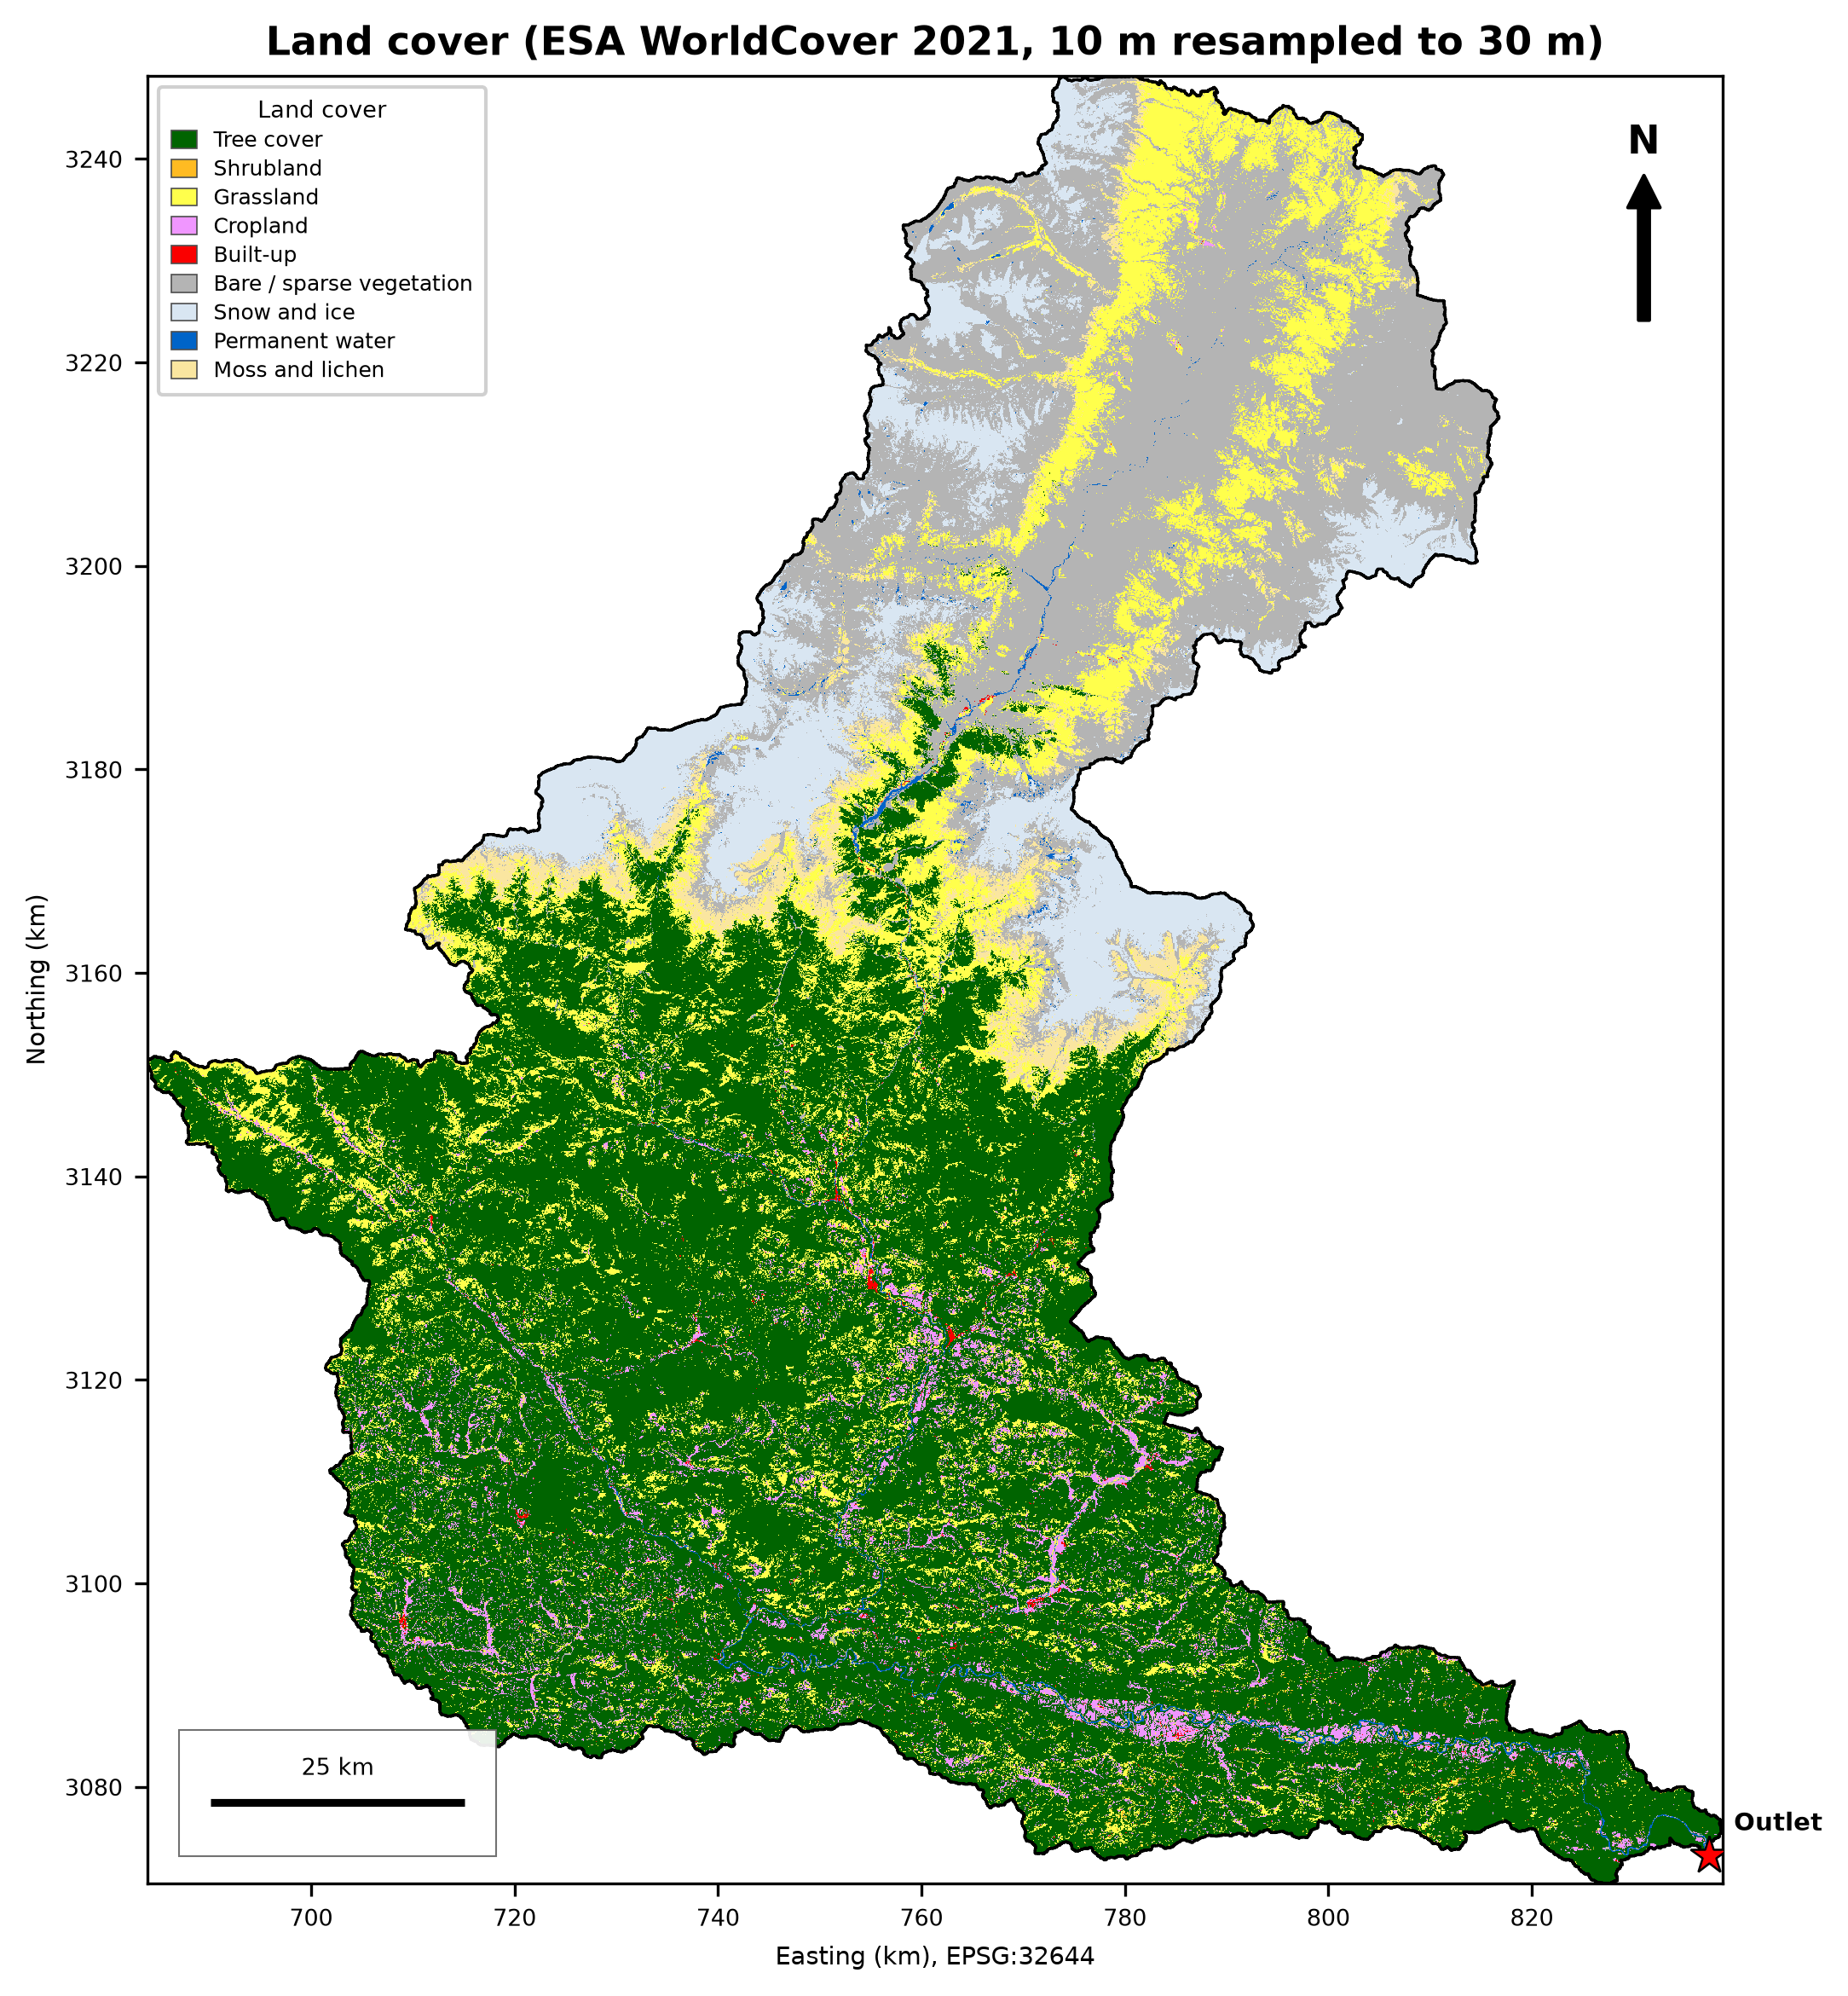

© ESA WorldCover project 2021 / Contains modified Copernicus Sentinel data (2021) processed by ESA WorldCover consortium

Above 5,000 m: 1,987 km2 (16.7 % of basin)
  Snow and ice              :  42.9 % of that area
  Bare / sparse vegetation  :  52.9 % of that area
  Moss and lichen           :   1.8 % of that area


,sub_id,lc_tree_cover_pct,lc_shrubland_pct,lc_grassland_pct,lc_cropland_pct,lc_built-up_pct,lc_bare_sparse_vegetation_pct,lc_snow_and_ice_pct,lc_permanent_water_pct,lc_moss_and_lichen_pct,dominant_landcover
0,1,85.88,1.01,4.30,6.15,0.25,0.73,0.0,1.68,0.00,Tree cover
1,2,77.66,0.74,6.92,12.99,0.59,0.25,0.0,0.85,0.00,Tree cover
2,3,82.29,0.30,6.75,7.83,0.37,0.69,0.0,1.76,0.00,Tree cover
3,4,86.62,0.07,6.40,3.97,0.33,0.91,0.0,1.71,0.00,Tree cover
4,5,77.82,0.14,12.01,6.88,0.65,0.70,0.0,1.82,0.00,Tree cover
5,6,77.10,0.00,14.36,7.70,0.19,0.18,0.0,0.47,0.00,Tree cover
6,7,76.25,0.00,14.95,6.66,1.29,0.24,0.0,0.62,0.00,Tree cover
7,8,78.99,0.00,17.93,0.53,0.21,0.92,0.0,0.17,1.26,Tree cover


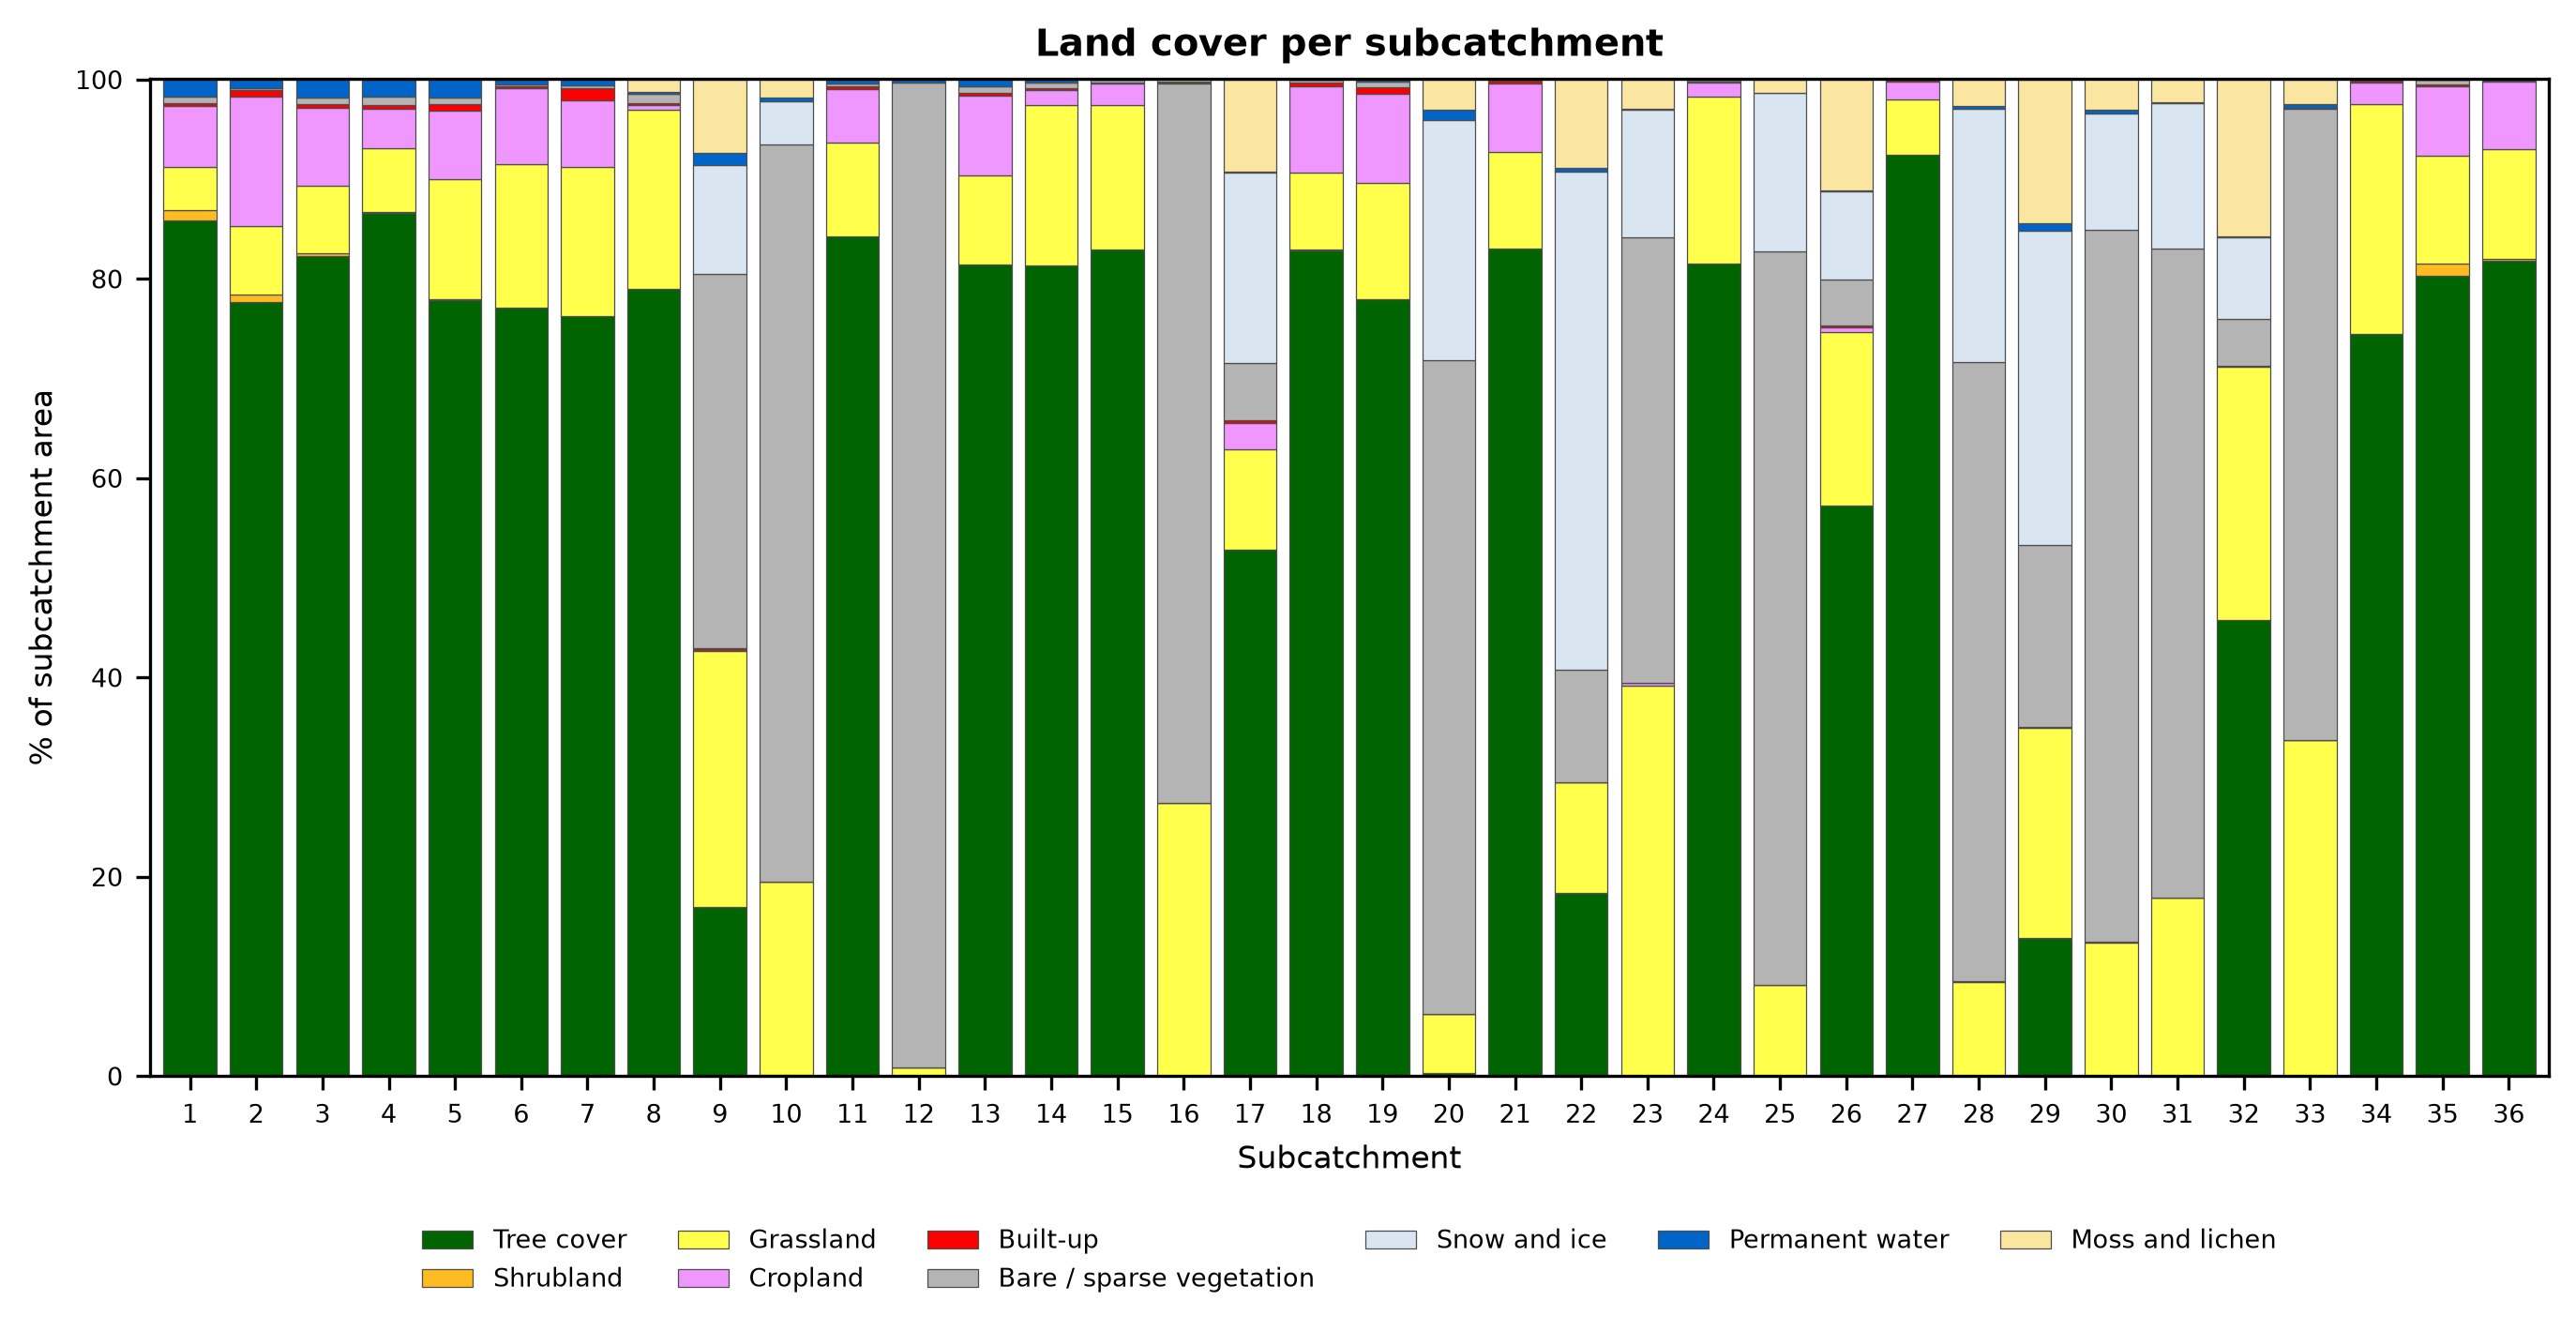

d:\miniconda\envs\kgflood\Lib\site-packages\rasterio\features.py:129: RuntimeWarning: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.
  yield from _shapes(source, mask, connectivity, transform)


land cover polygons: 8 features (2 s)


In [2]:
# ============================================================
# Cell 2: land cover (ESA WorldCover 2021) - raster, maps, polygons, tables, shares per subcatchment
# ============================================================
LC_PATH = P.RAS / "landcover_worldcover.tif"
WC_T = {10: ("Tree cover", "#006400"), 20: ("Shrubland", "#ffbb22"), 30: ("Grassland", "#ffff4c"),
        40: ("Cropland", "#f096ff"), 50: ("Built-up", "#fa0000"), 60: ("Bare / sparse vegetation", "#b4b4b4"),
        70: ("Snow and ice", "#d9e6f2"), 80: ("Permanent water", "#0064c8"),
        90: ("Herbaceous wetland", "#0096a0"), 95: ("Mangroves", "#00cf75"), 100: ("Moss and lichen", "#fae6a0")}

if LC_PATH.exists():
    lc = np.nan_to_num(read_grid(LC_PATH), nan=0).astype("uint8")
    assert lc.shape == (H, W)
    print("Loaded cached land cover (delete landcover_worldcover.tif to fetch it again)")
else:
    import pystac_client, planetary_computer
    os.environ.update(GDAL_HTTP_MAX_RETRY="5", GDAL_HTTP_RETRY_DELAY="3",
                      GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.vrt")
    w_, s_, e_, n_ = ws.boundary.to_crs(4326).total_bounds
    cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=planetary_computer.sign_inplace)
    items = list(cat.search(collections=["esa-worldcover"], bbox=[w_, s_, e_, n_]).items())
    versions = sorted({it.properties.get("esa_worldcover:product_version") for it in items if it.properties})
    ver = max(v for v in versions if v)
    sel = [it for it in items if it.properties.get("esa_worldcover:product_version") == ver]
    print(f"WorldCover version {ver}: {[it.id for it in sel]}")
    assert sel and all("map" in it.assets for it in sel), "unexpected assets"
    lc = np.zeros((H, W), dtype="uint8")
    for it in sel:
        t0 = time.time()
        with rasterio.open(it.assets["map"].href) as src:
            reproject(source=rasterio.band(src, 1), destination=lc, dst_transform=ws.transform,
                      dst_crs=ws.crs, resampling=Resampling.mode, src_nodata=0, dst_nodata=0,
                      init_dest_nodata=False)
        print(f"  {it.id}: {time.time() - t0:.0f} s")
    lc[~ws.mask] = 0
    ws.save(np.where(lc > 0, lc, np.nan).astype("float32"), LC_PATH, nodata=0, dtype="uint8")

print(f"Basin cells without land cover: {int((ws.mask & (lc == 0)).sum()):,} (expect 0)")

# ---------- classes, map, table ----------
tab_lc = area_table(lc, WC_T)
save_table(tab_lc, P.TAB / "05_landcover_classes.csv"); display(tab_lc)
idx_lc, codes_lc = class_map(lc, WC_T, "05_landcover.png",
                             "Land cover (ESA WorldCover 2021, 10 m resampled to 30 m)", "Land cover")
print("© ESA WorldCover project 2021 / Contains modified Copernicus Sentinel data (2021) "
      "processed by ESA WorldCover consortium")

# ---------- high mountains ----------
dem = read_grid(P.RAS / "dem.tif")
hi_ = ws.mask & (dem >= 5000)
print(f"\nAbove 5,000 m: {hi_.sum() * ws.cell_area_km2:,.0f} km2 ({100 * hi_.sum() / ws.n_cells:.1f} % of basin)")
for c in (70, 60, 100):
    print(f"  {WC_T[c][0]:<26}: {100 * ((lc == c) & hi_).sum() / max(hi_.sum(), 1):5.1f} % of that area")
del dem, hi_

# ---------- shares per subcatchment ----------
slug = lambda s: s.lower().replace(" / ", "_").replace(" ", "_")
Mlc = counts_by_sub(np.nan_to_num(idx_lc, nan=0).astype("int32"), len(codes_lc))[:, 1:]
lc_cols = [f"lc_{slug(WC_T[c][0])}_pct" for c in codes_lc]
lc_sub = pd.DataFrame(100 * Mlc / Mlc.sum(axis=1, keepdims=True), columns=lc_cols).round(2)
lc_sub.insert(0, "sub_id", np.arange(1, N_SUB + 1))
lc_sub["dominant_landcover"] = [WC_T[codes_lc[k]][0] for k in Mlc.argmax(axis=1)]
save_table(lc_sub, P.TAB / "05_subcatchment_landcover.csv")
display(lc_sub.head(8))
stacked_bars(lc_sub, lc_cols, [WC_T[c][0] for c in codes_lc], [WC_T[c][1] for c in codes_lc],
             "05_landcover_by_subcatchment.png", "Land cover per subcatchment")

# ---------- polygons (small patches merged; raise sieve_px for smaller files) ----------
t0 = time.time()
g_lc = classes_to_vector(idx_lc, ws, [WC_T[c][0] for c in codes_lc], P.VEC / "landcover", sieve_px=500)
print(f"land cover polygons: {len(g_lc)} features ({time.time() - t0:.0f} s)")

  sand 0-5cm: 0.44 MB in 2 s
  clay 0-5cm: 0.42 MB in 2 s
  sand 5-15cm: 0.44 MB in 2 s
  clay 5-15cm: 0.43 MB in 2 s
  sand 15-30cm: 0.44 MB in 2 s
  clay 15-30cm: 0.43 MB in 2 s
  sand 30-60cm: 0.44 MB in 2 s
  clay 30-60cm: 0.44 MB in 2 s
  sand 60-100cm: 0.44 MB in 2 s
  clay 60-100cm: 0.44 MB in 2 s

Soil window (691, 707): no-data pixels filled from the nearest valid pixel: 6.1 %
Mean sand 41 % | mean clay 22 % over the window
Basin cells without a soil group: 0 (expect 0)


,group,mean_0_100cm_pct,restrictive_0_60cm_pct
0,A,9.13,6.49
1,B,63.84,61.35
2,C,0.11,0.34
3,D,26.92,31.81


Cells whose group differs between the two methods: 8.0 % | method used: mean


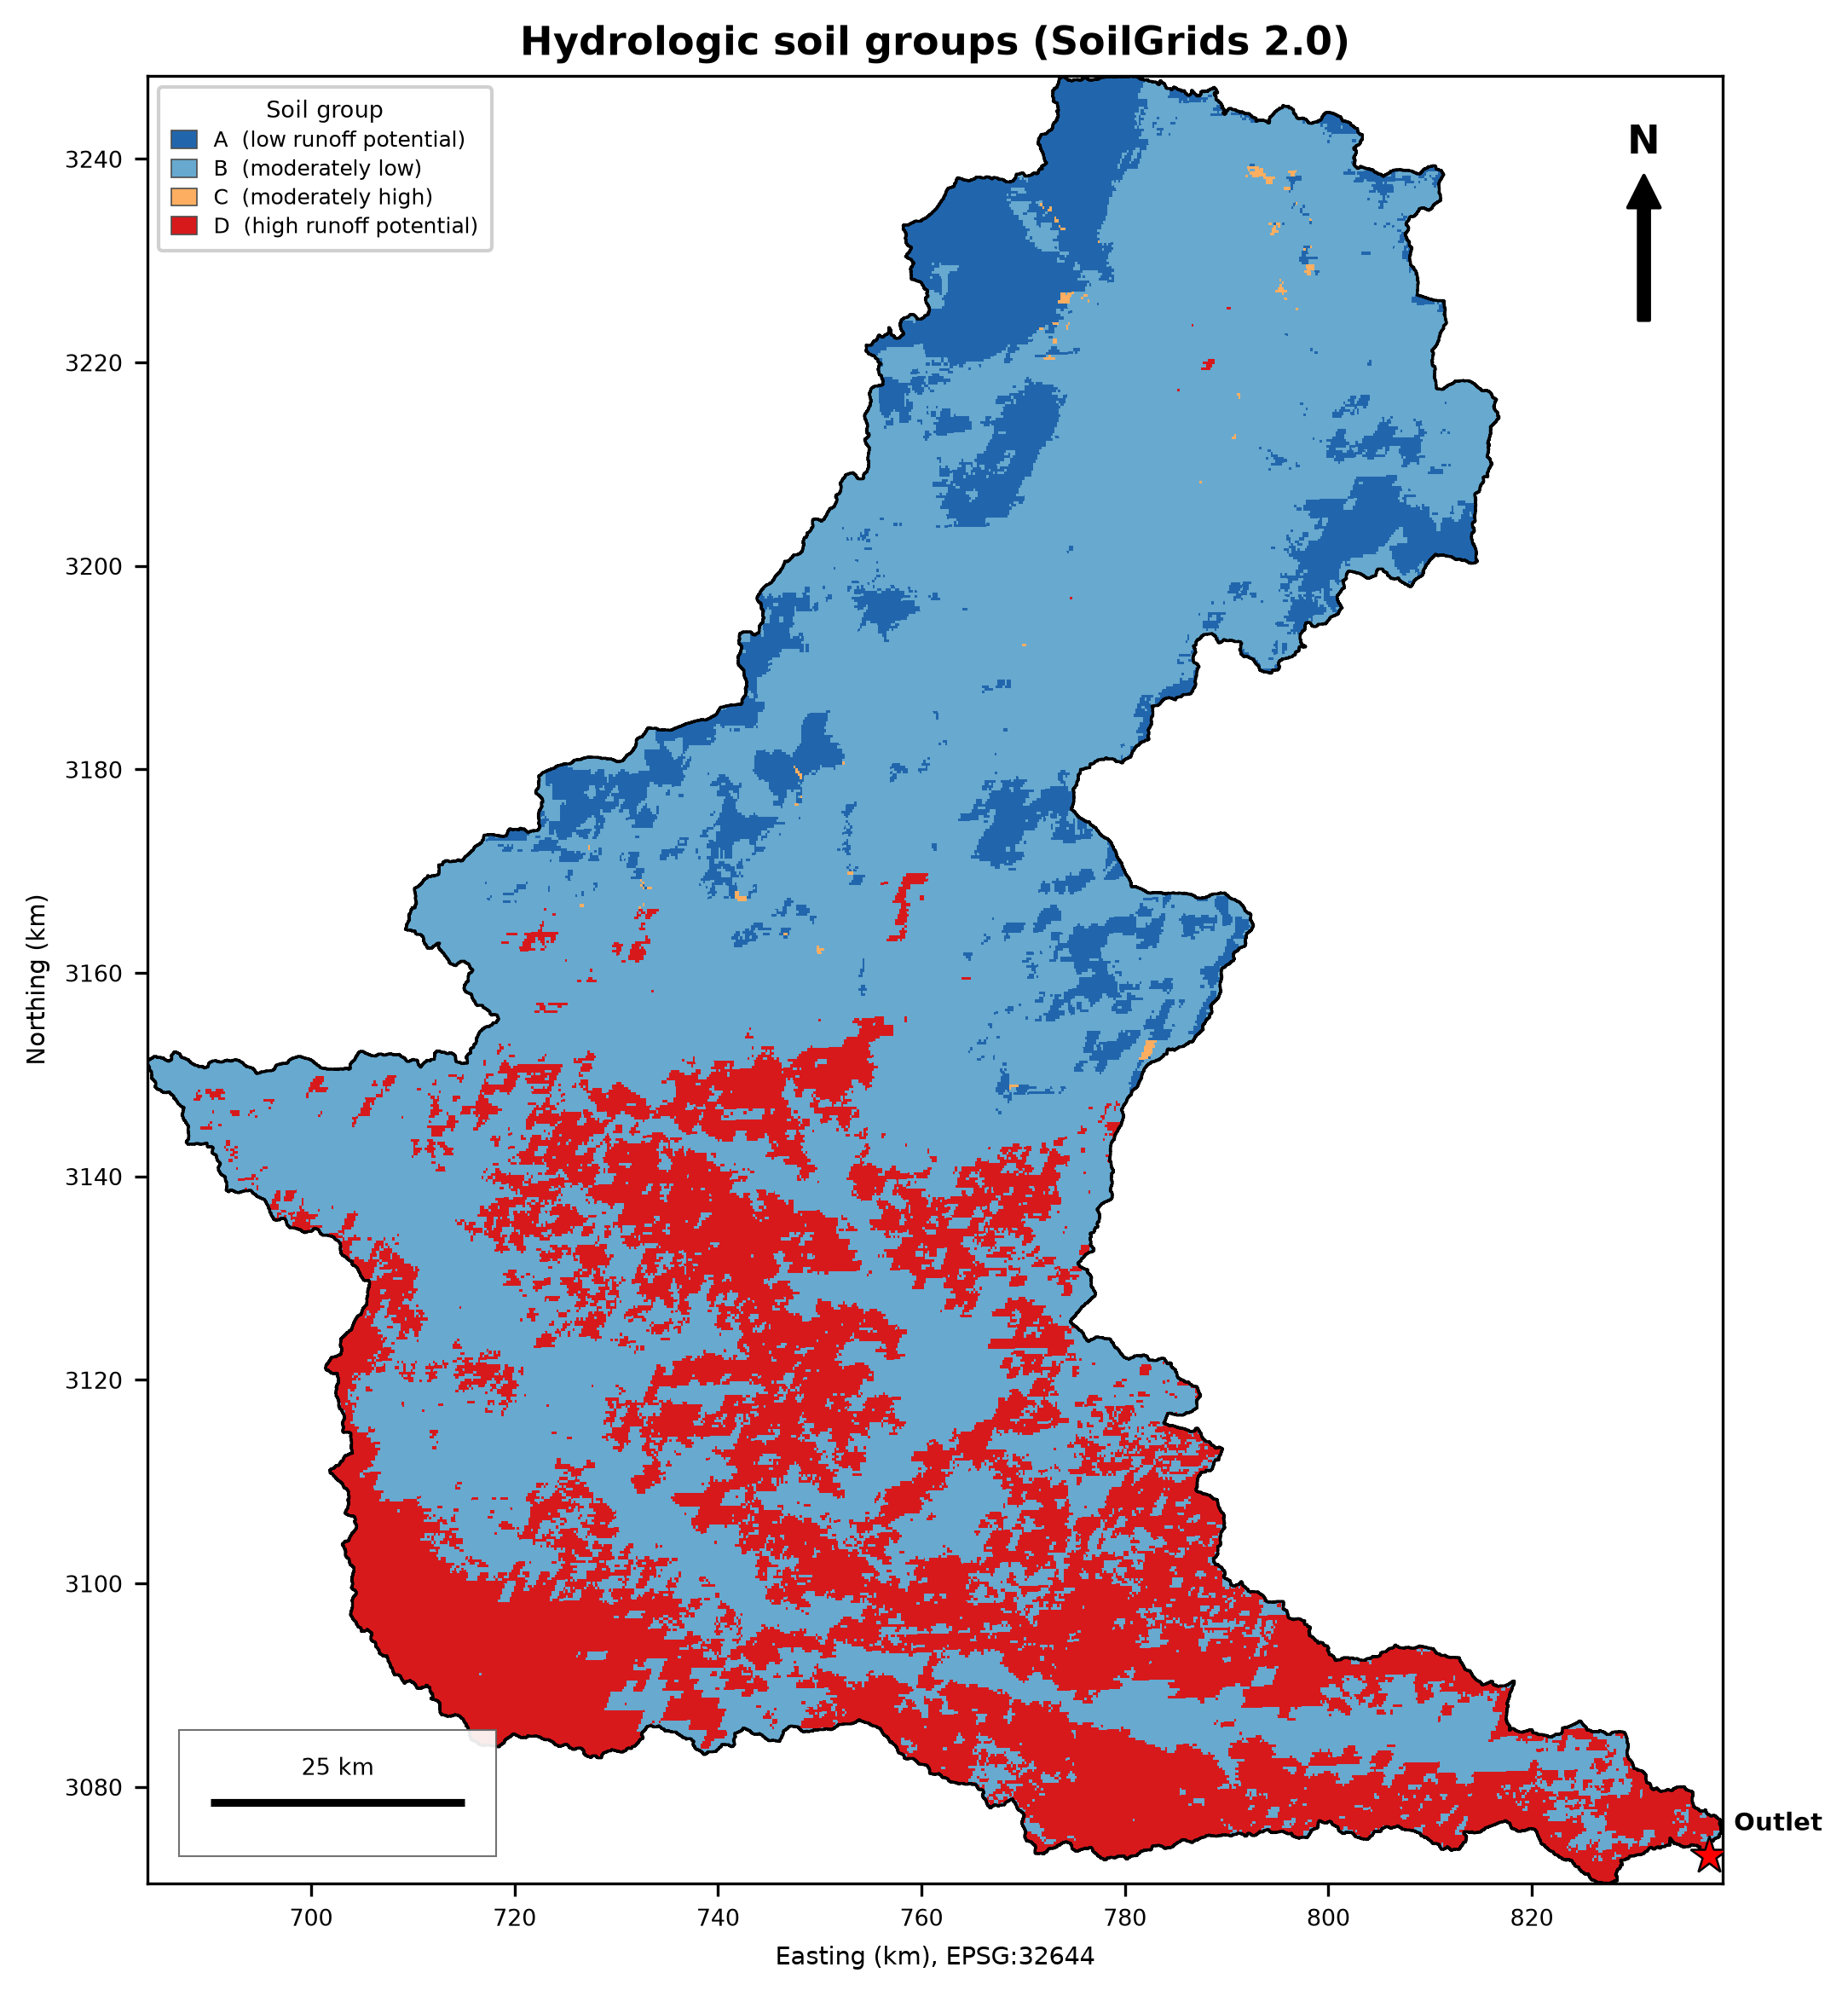

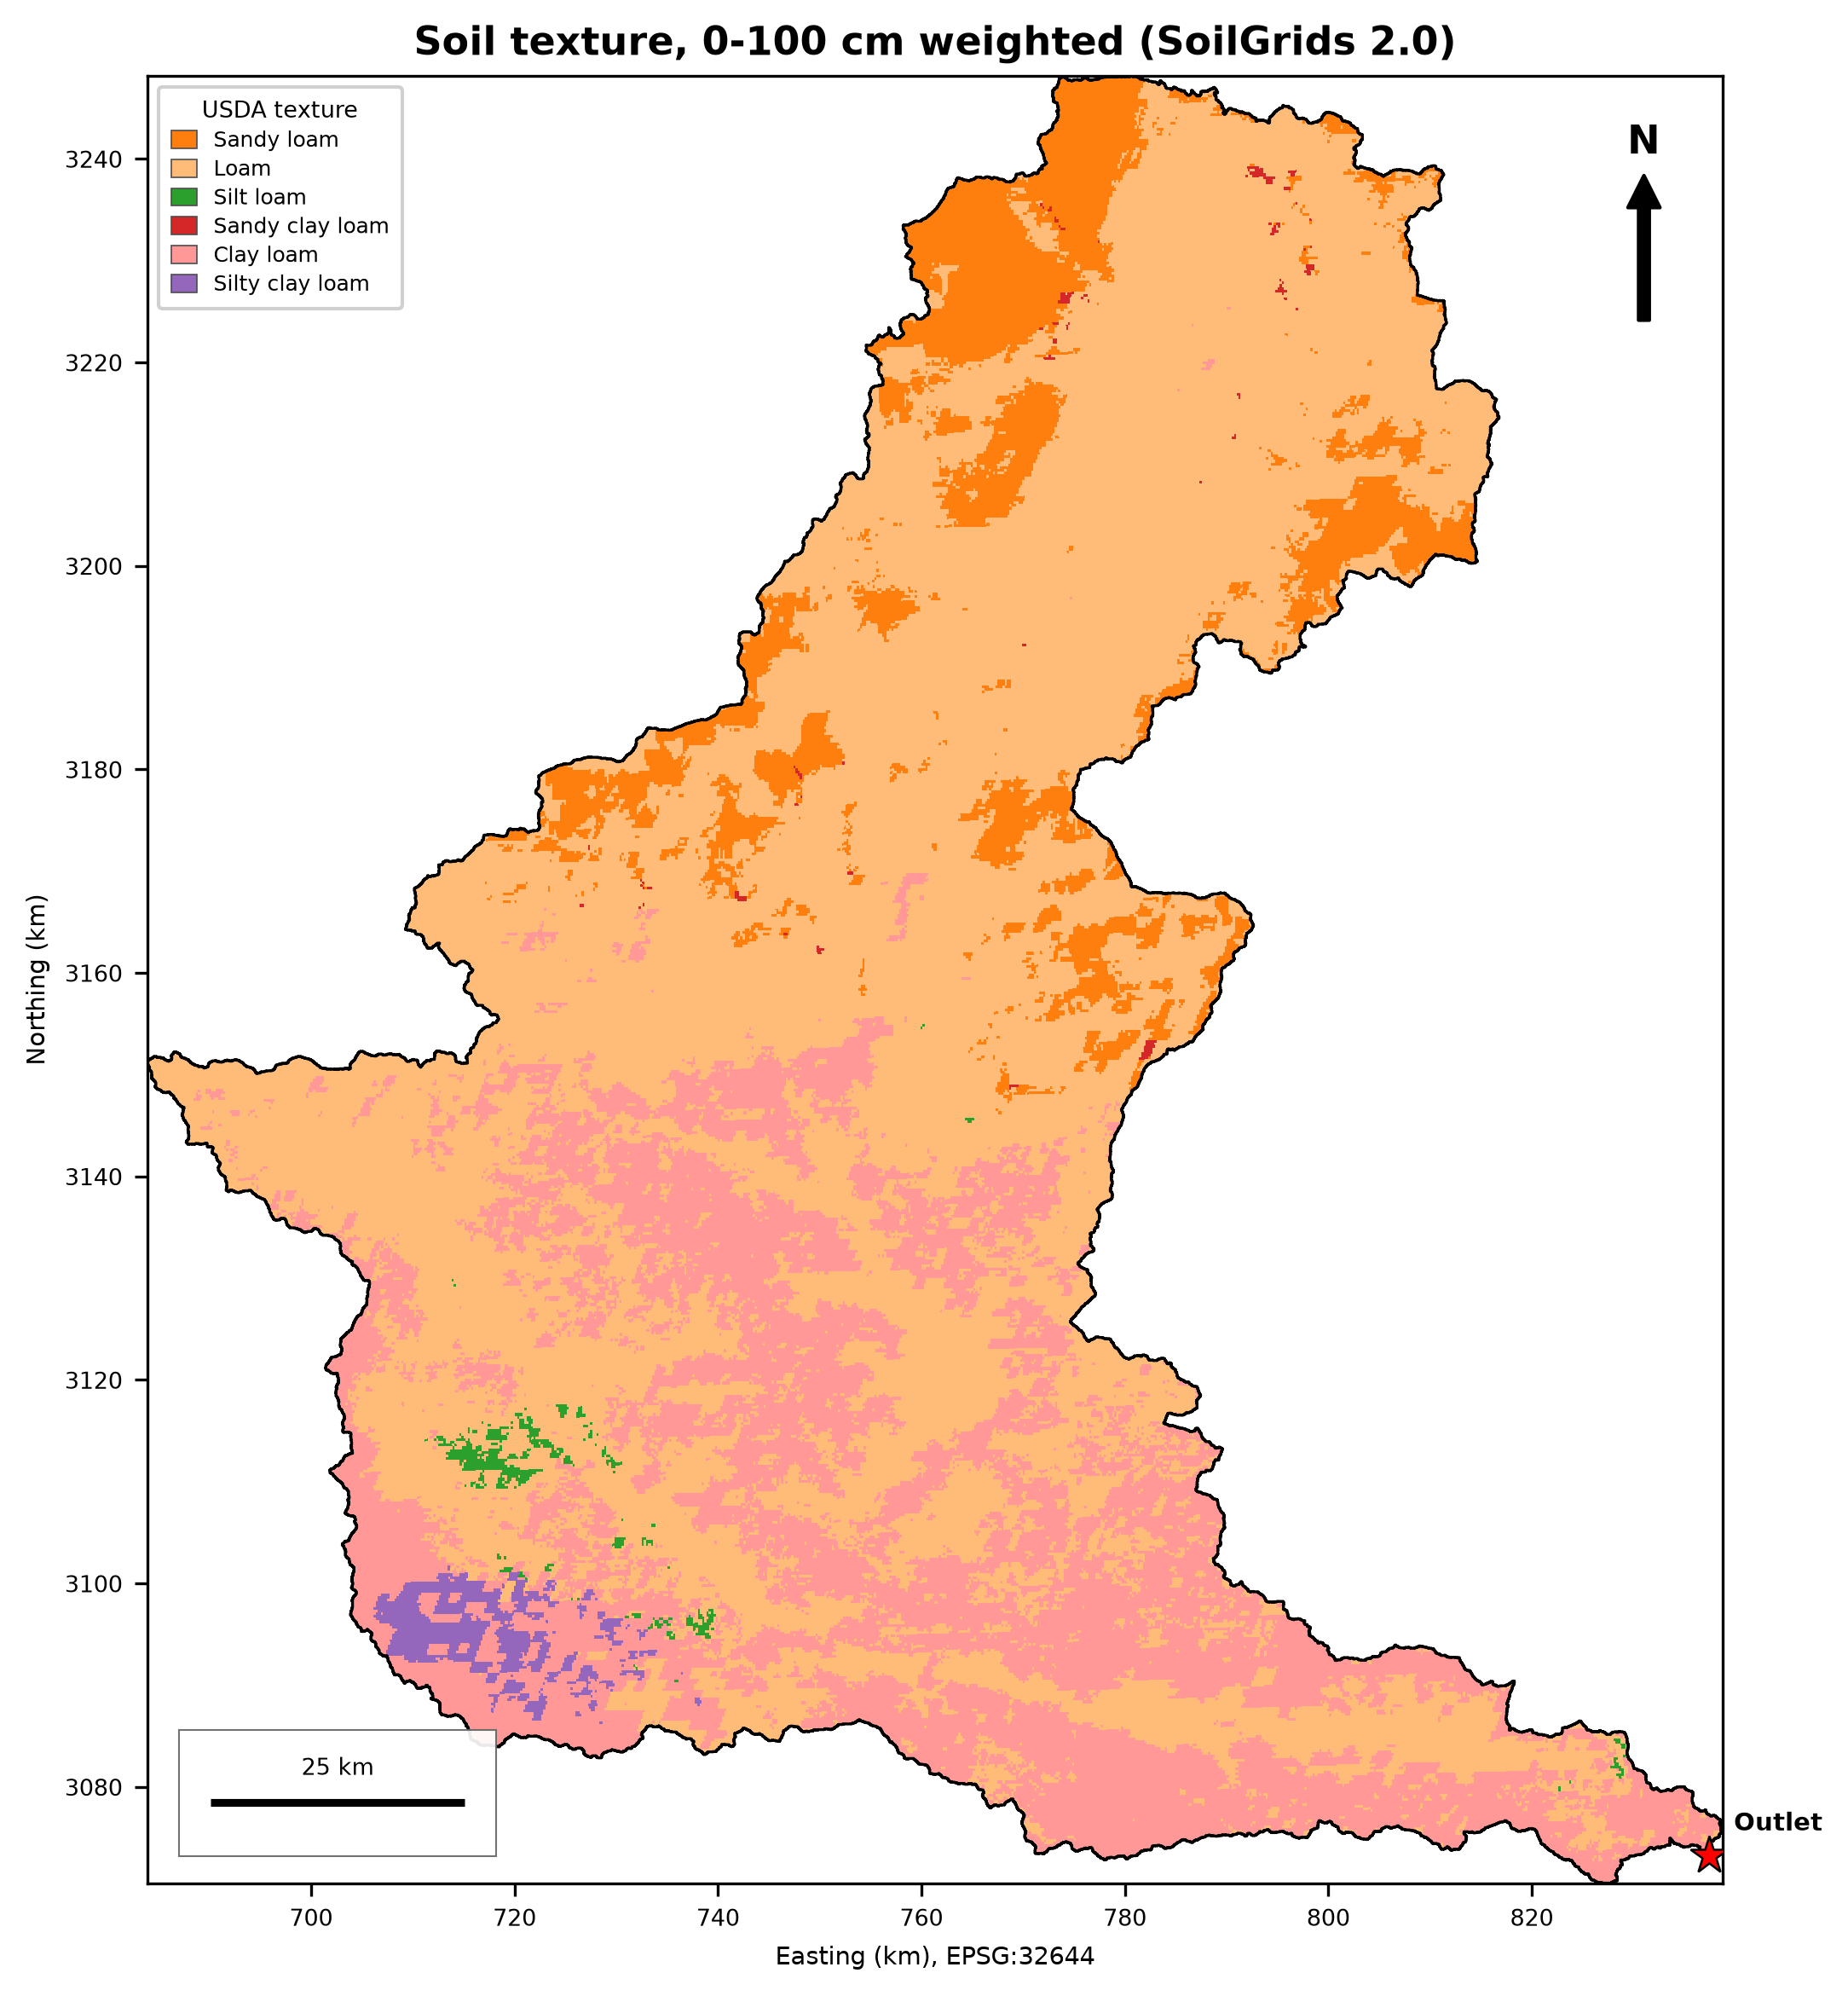

,code,class,cells,area_km2,percent
0,1,A (low runoff potential),1245038,1084.43,9.13
1,2,B (moderately low),8701972,7579.43,63.84
2,3,C (moderately high),15526,13.52,0.11
3,4,D (high runoff potential),3668999,3195.70,26.92


,code,class,cells,area_km2,percent
0,3,Sandy loam,1245038,1084.43,9.13
1,4,Loam,8652845,7536.64,63.48
2,5,Silt loam,49127,42.79,0.36
3,7,Sandy clay loam,15526,13.52,0.11
4,8,Clay loam,3530859,3075.38,25.90
5,9,Silty clay loam,138140,120.32,1.01


,sub_id,hsg_A_pct,hsg_B_pct,hsg_C_pct,hsg_D_pct,dominant_hsg,dominant_texture,mean_sand_pct,mean_clay_pct
0,1,0.00,42.80,0.0,57.20,D,Clay loam,33.10,27.06
1,2,0.00,35.95,0.0,64.05,D,Clay loam,32.71,27.67
2,3,0.00,40.24,0.0,59.76,D,Clay loam,32.58,27.43
3,4,0.00,64.00,0.0,36.00,B,Loam,27.84,26.44
4,5,0.00,57.91,0.0,42.09,B,Loam,31.70,26.55
5,6,0.00,54.38,0.0,45.62,B,Loam,34.64,26.53
6,7,0.00,48.17,0.0,51.83,D,Clay loam,34.00,26.77
7,8,1.02,81.35,0.0,17.63,B,Loam,37.47,23.01


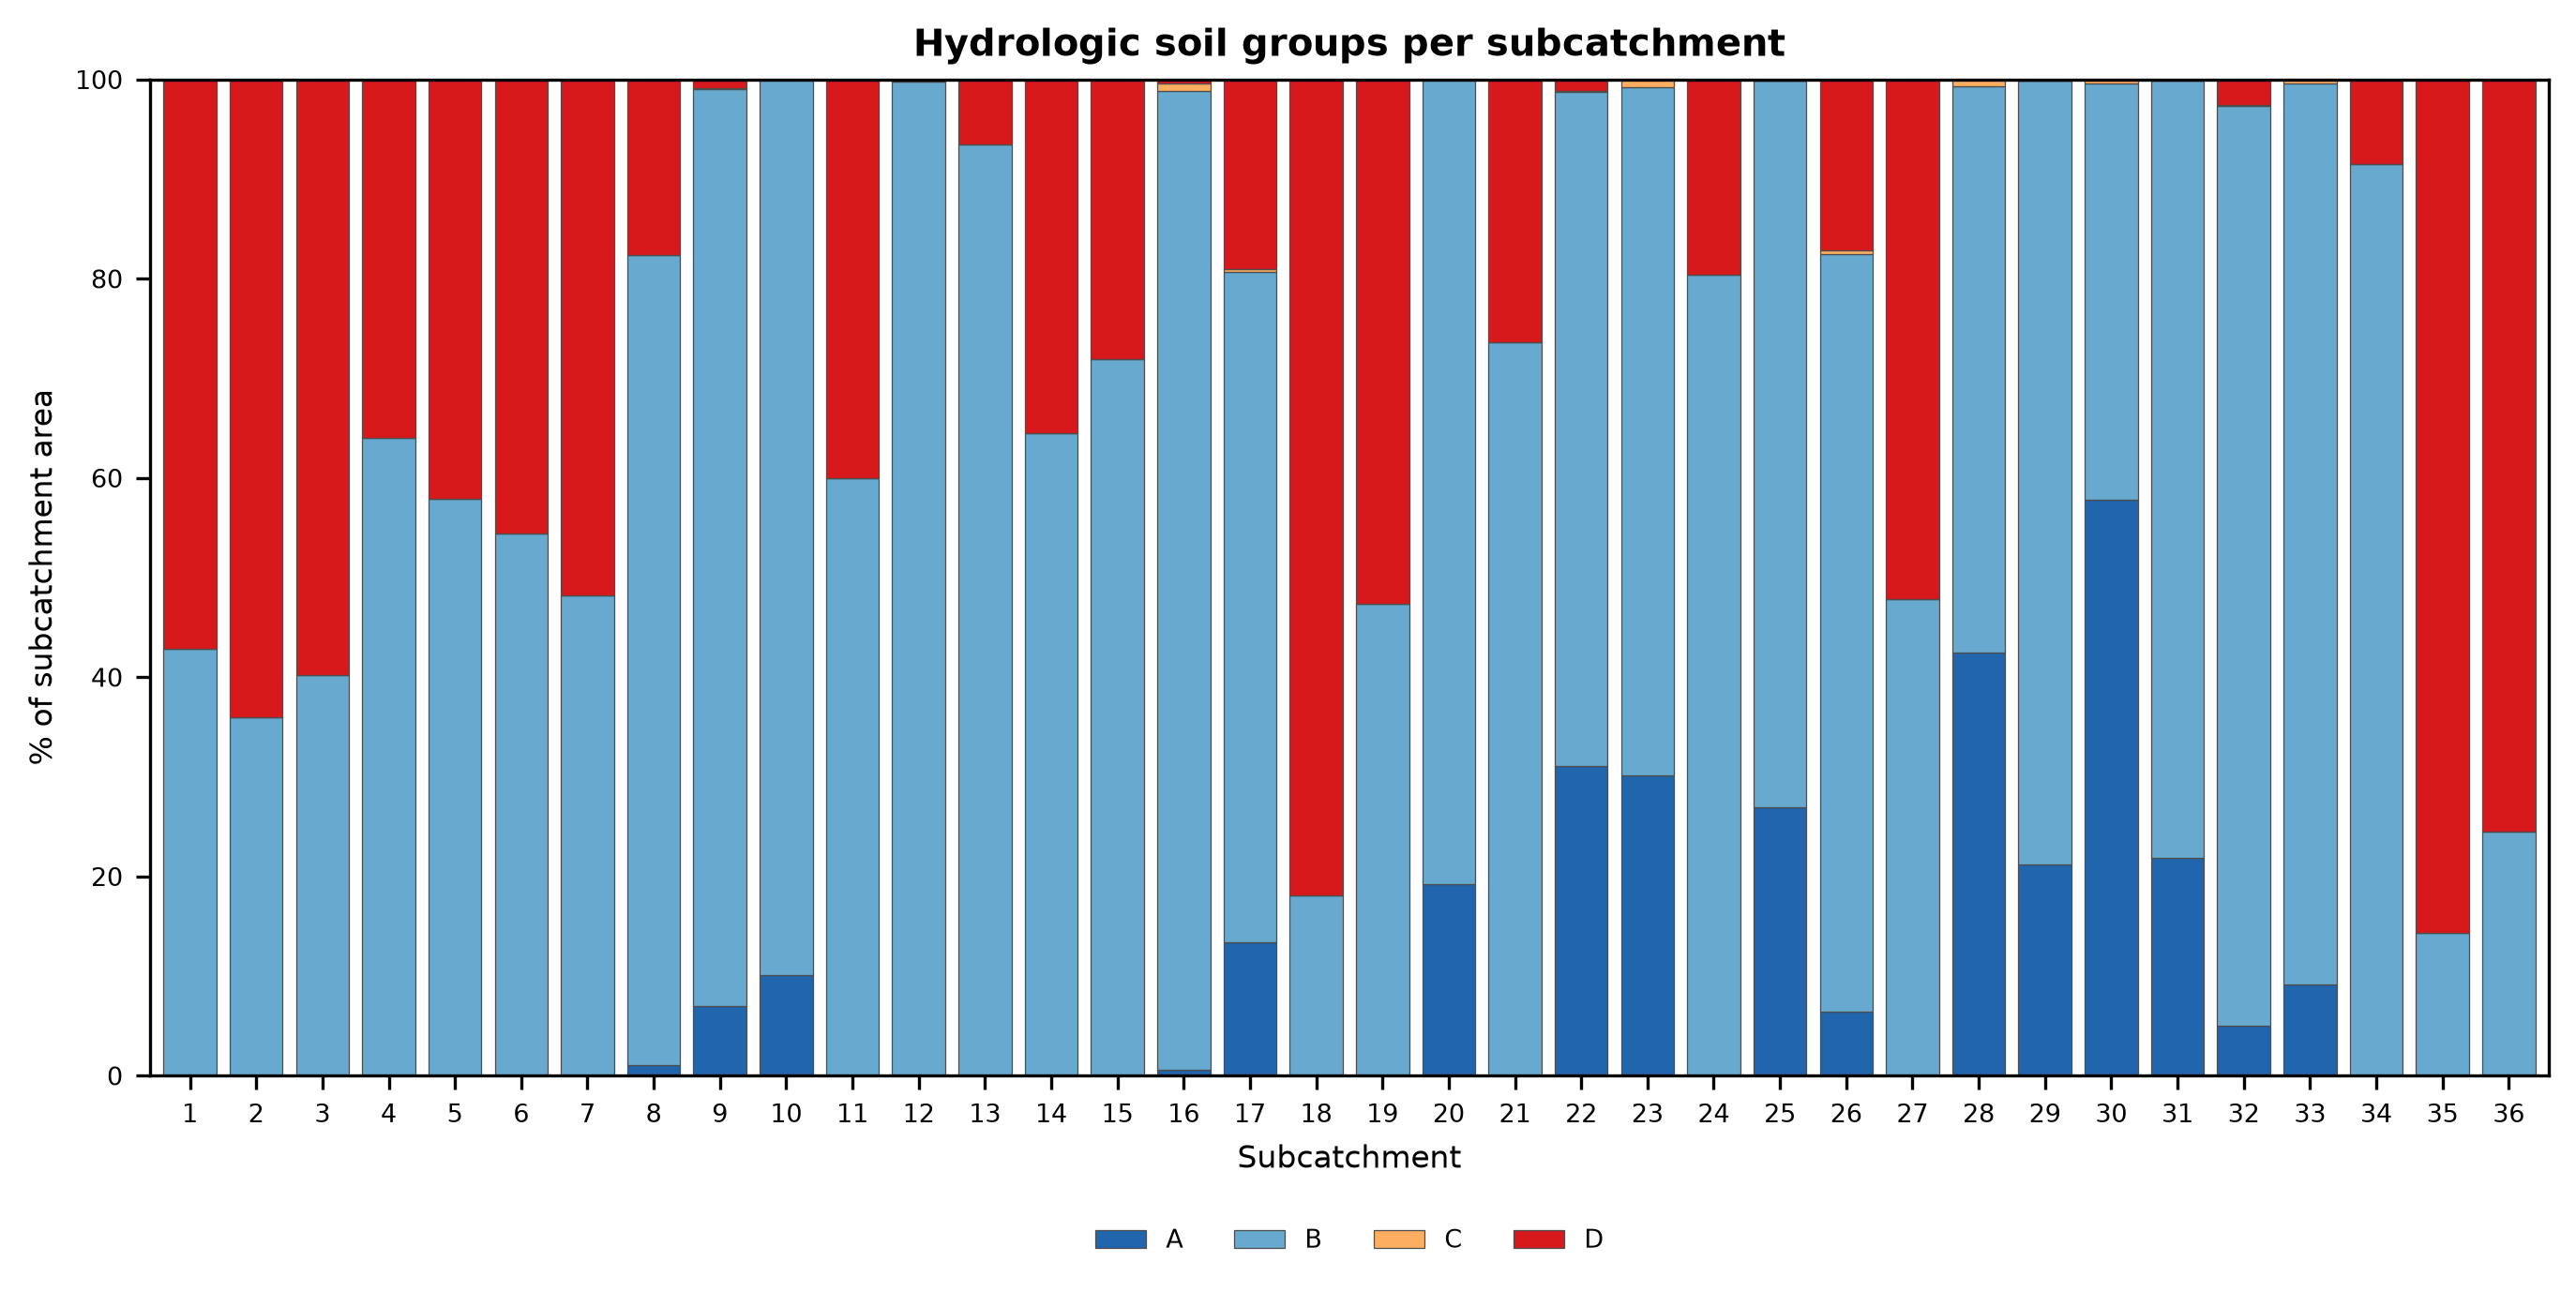

Soil data: SoilGrids 2.0 (ISRIC), CC-BY 4.0


In [3]:
# ============================================================
# Cell 3: soil - SoilGrids 2.0 (WCS window) -> texture -> hydrologic soil group
# ============================================================
SOIL_DIR = P.INPUTS / "soilgrids_wcs_cache"
SOIL_DIR.mkdir(exist_ok=True)
LAYERS = [("0-5cm", 5), ("5-15cm", 10), ("15-30cm", 15), ("30-60cm", 30), ("60-100cm", 40)]   # depth, thickness (cm)
HSG_METHOD = "mean"      # "mean" = thickness-weighted sand/clay over 0-100 cm | "restrictive" = worst layer in 0-60 cm
HEAD = {"User-Agent": "Mozilla/5.0"}
TEX = ["Sand", "Loamy sand", "Sandy loam", "Loam", "Silt loam", "Silt", "Sandy clay loam",
       "Clay loam", "Silty clay loam", "Sandy clay", "Silty clay", "Clay"]            # codes 1..12

w_, s_, e_, n_ = ws.boundary.to_crs(4326).total_bounds
pad = 0.02
w_, s_, e_, n_ = w_ - pad, s_ - pad, e_ + pad, n_ + pad
crs_uri = "http://www.opengis.net/def/crs/EPSG/0/4326"

# ---------- editable texture -> HSG lookup (kept if it already exists) ----------
HSG_LOOKUP = P.INPUTS / "hsg_lookup.csv"
if not HSG_LOOKUP.exists():
    pd.DataFrame({"texture_code": range(1, 13), "texture": TEX,
                  "hsg": ["A", "A", "A", "B", "B", "B", "C", "D", "D", "D", "D", "D"]}
                 ).to_csv(HSG_LOOKUP, index=False)
hl = pd.read_csv(HSG_LOOKUP)
hsg_lut = np.zeros(13, dtype="uint8")
for code, g in zip(hl.texture_code, hl.hsg):
    hsg_lut[int(code)] = "ABCD".index(str(g).strip().upper()[0]) + 1


def get_soil(var, depth, tries=3):
    f = SOIL_DIR / f"{var}_{depth}.tif"
    if f.exists():
        return f
    url = (f"https://maps.isric.org/mapserv?map=/map/{var}.map&SERVICE=WCS&VERSION=2.0.1&REQUEST=GetCoverage"
           f"&COVERAGEID={var}_{depth}_mean&FORMAT=image/tiff&SUBSET=long({w_:.4f},{e_:.4f})"
           f"&SUBSET=lat({s_:.4f},{n_:.4f})&SUBSETTINGCRS={crs_uri}&OUTPUTCRS={crs_uri}")
    for k in range(tries):
        try:
            t0 = time.time()
            r = requests.get(url, timeout=300, headers=HEAD)
            r.raise_for_status()
            with MemoryFile(r.content) as mf, mf.open() as ds:           # confirm it is a real GeoTIFF
                ds.read(1, window=((0, 1), (0, 1)))
            f.write_bytes(r.content)
            print(f"  {var} {depth}: {len(r.content) / 1e6:.2f} MB in {time.time() - t0:.0f} s")
            return f
        except Exception as ex:
            print(f"  {var} {depth}: attempt {k + 1} failed ({type(ex).__name__}: {str(ex)[:80]})")
            time.sleep(10)
    raise RuntimeError(f"Could not download {var} {depth}")


def texture_codes(sand, silt, clay):
    """USDA texture class (1..12; 0 = no data) from percentages."""
    conds = [(clay >= 40) & (sand <= 45) & (silt < 40),                                   # clay
             (clay >= 40) & (silt >= 40),                                                 # silty clay
             (clay >= 35) & (sand > 45),                                                  # sandy clay
             (clay >= 27) & (clay < 40) & (sand <= 20),                                   # silty clay loam
             (clay >= 27) & (clay < 40) & (sand > 20) & (sand <= 45),                     # clay loam
             (clay >= 20) & (clay < 35) & (silt < 28) & (sand > 45),                      # sandy clay loam
             (clay >= 7) & (clay < 27) & (silt >= 28) & (silt < 50) & (sand <= 52),       # loam
             ((silt >= 50) & (clay >= 12) & (clay < 27)) | ((silt >= 50) & (silt < 80) & (clay < 12)),  # silt loam
             (silt >= 80) & (clay < 12),                                                  # silt
             ((clay >= 7) & (clay < 20) & (sand > 52) & ((silt + 2 * clay) >= 30))
             | ((clay < 7) & (silt < 50) & ((silt + 2 * clay) >= 30)),                    # sandy loam
             ((silt + 1.5 * clay) >= 15) & ((silt + 2 * clay) < 30),                      # loamy sand
             (silt + 1.5 * clay) < 15]                                                    # sand
    return np.select(conds, [12, 11, 10, 9, 8, 7, 4, 5, 6, 3, 2, 1], default=0).astype("uint8")


def fill_nearest(*arrs, mask):
    if not mask.any() or mask.all():
        return arrs
    nn = ndimage.distance_transform_edt(mask, return_distances=False, return_indices=True)
    return tuple(a[tuple(nn)] for a in arrs)


# ---------- 1) download and weight (sand and clay; silt by difference) ----------
print("Downloading SoilGrids windows (cached afterwards):")
sand_w, clay_w, wsum, layer_pct, shape0 = 0, 0, 0, [], None
for depth, th in LAYERS:
    fs, fc = get_soil("sand", depth), get_soil("clay", depth)
    with rasterio.open(fs) as a, rasterio.open(fc) as b:
        sa, cl = a.read(1).astype("float32"), b.read(1).astype("float32")
        soil_tf, soil_crs = a.transform, a.crs
    shape0 = shape0 or sa.shape
    assert sa.shape == cl.shape == shape0, "layers are on different grids"
    ok_ = (sa >= 0) & (cl >= 0) & ((sa + cl) > 0)                        # negative or 0/0 = water or no data
    sp, cp = np.where(ok_, sa, np.nan) / 10.0, np.where(ok_, cl, np.nan) / 10.0      # g/kg -> %
    layer_pct.append((depth, sp, cp))
    sand_w = sand_w + np.nan_to_num(sp) * th
    clay_w = clay_w + np.nan_to_num(cp) * th
    wsum = wsum + ok_ * th
bad = wsum == 0
gap_pct = 100 * bad.mean()
sand_m = np.where(bad, 0, sand_w / np.maximum(wsum, 1)).astype("float32")
clay_m = np.where(bad, 0, clay_w / np.maximum(wsum, 1)).astype("float32")
silt_m = np.clip(100 - sand_m - clay_m, 0, 100).astype("float32")

# ---------- 2) texture and HSG, both methods ----------
tex_mean = texture_codes(sand_m, silt_m, clay_m)
tex_mean[bad] = 0
hsg_layers = []
for depth, sp, cp in layer_pct[:4]:                                      # layers down to 60 cm
    hsg_layers.append(hsg_lut[texture_codes(sp, np.clip(100 - sp - cp, 0, 100), cp)])
hsg_restr = np.maximum.reduce(hsg_layers)
tex_mean, sand_m, clay_m = fill_nearest(tex_mean, sand_m, clay_m, mask=bad)
(hsg_restr,) = fill_nearest(hsg_restr, mask=(hsg_restr == 0))
hsg_mean = hsg_lut[tex_mean]
print(f"\nSoil window {shape0}: no-data pixels filled from the nearest valid pixel: {gap_pct:.1f} %")
print(f"Mean sand {sand_m.mean():.0f} % | mean clay {clay_m.mean():.0f} % over the window")

# ---------- 3) warp to the basin grid (nearest = honest 250 m blocks) ----------
def to_grid(arr, dtype, nodata=None):
    out = np.full((H, W), 0 if nodata is None else nodata, dtype=dtype)
    reproject(source=arr, destination=out, src_transform=soil_tf, src_crs=soil_crs,
              dst_transform=ws.transform, dst_crs=ws.crs, resampling=Resampling.nearest,
              src_nodata=nodata, dst_nodata=nodata)
    return out

tex_g  = np.where(ws.mask, to_grid(tex_mean, "uint8", 0), 0).astype("uint8")
hsg_m  = np.where(ws.mask, to_grid(hsg_mean, "uint8", 0), 0).astype("uint8")
hsg_r  = np.where(ws.mask, to_grid(hsg_restr, "uint8", 0), 0).astype("uint8")
sand_g = np.where(ws.mask, to_grid(sand_m, "float32"), np.nan).astype("float32")
clay_g = np.where(ws.mask, to_grid(clay_m, "float32"), np.nan).astype("float32")
hsg = hsg_m if HSG_METHOD == "mean" else hsg_r
print(f"Basin cells without a soil group: {int((ws.mask & (hsg == 0)).sum()):,} (expect 0)")

# ---------- 4) how much does the method matter? ----------
inb = ws.mask
sens = pd.DataFrame({"group": list("ABCD")})
for nm, a in (("mean_0_100cm_pct", hsg_m), ("restrictive_0_60cm_pct", hsg_r)):
    sens[nm] = [round(100 * (a[inb] == k).sum() / inb.sum(), 2) for k in (1, 2, 3, 4)]
save_table(sens, P.TAB / "05_soil_hsg_sensitivity.csv"); display(sens)
print(f"Cells whose group differs between the two methods: {100 * (hsg_m[inb] != hsg_r[inb]).mean():.1f} % "
      f"| method used: {HSG_METHOD}")

# ---------- 5) save rasters ----------
def save_codes(a, name):
    ws.save(np.where(a > 0, a, np.nan).astype("float32"), P.RAS / name, nodata=0, dtype="uint8")
save_codes(hsg, "hsg.tif")
save_codes(tex_g, "soil_texture.tif")
ws.save(sand_g, P.RAS / "soil_sand_pct.tif")
ws.save(clay_g, P.RAS / "soil_clay_pct.tif")

# ---------- 6) maps, tables, polygons ----------
HSG_T = {1: ("A  (low runoff potential)", "#2166ac"), 2: ("B  (moderately low)", "#67a9cf"),
         3: ("C  (moderately high)", "#fdae61"), 4: ("D  (high runoff potential)", "#d7191c")}
tab20 = plt.get_cmap("tab20")
TEX_T = {i + 1: (TEX[i], mcolors.to_hex(tab20(i))) for i in range(12)}
idx_h, codes_h = class_map(hsg, HSG_T, "05_hsg.png", "Hydrologic soil groups (SoilGrids 2.0)", "Soil group")
idx_t, codes_t = class_map(tex_g, TEX_T, "05_soil_texture.png", "Soil texture, 0-100 cm weighted (SoilGrids 2.0)", "USDA texture")
tab_hsg, tab_tex = area_table(hsg, HSG_T), area_table(tex_g, TEX_T)
save_table(tab_hsg, P.TAB / "05_soil_hsg_classes.csv"); save_table(tab_tex, P.TAB / "05_soil_texture_classes.csv")
display(tab_hsg); display(tab_tex)
classes_to_vector(idx_h, ws, [HSG_T[c][0] for c in codes_h], P.VEC / "hsg", sieve_px=20)
classes_to_vector(idx_t, ws, [TEX_T[c][0] for c in codes_t], P.VEC / "soil_texture", sieve_px=20)

# ---------- 7) shares per subcatchment ----------
Mh, Mt = counts_by_sub(hsg, 4), counts_by_sub(tex_g, 12)
soil_sub = pd.DataFrame({"sub_id": np.arange(1, N_SUB + 1)})
for j, g in enumerate("ABCD", start=1):
    soil_sub[f"hsg_{g}_pct"] = 100 * Mh[:, j] / Mh.sum(axis=1)
soil_sub["dominant_hsg"] = ["ABCD"[k] for k in Mh[:, 1:].argmax(axis=1)]
soil_sub["dominant_texture"] = [TEX[k] for k in Mt[:, 1:].argmax(axis=1)]
for nm, arr in (("mean_sand_pct", sand_g), ("mean_clay_pct", clay_g)):
    soil_sub[nm] = ndimage.mean(np.nan_to_num(arr), labels=sub, index=np.arange(1, N_SUB + 1))
soil_sub = soil_sub.round(2)
save_table(soil_sub, P.TAB / "05_subcatchment_soil.csv"); display(soil_sub.head(8))
stacked_bars(soil_sub, [f"hsg_{g}_pct" for g in "ABCD"], ["A", "B", "C", "D"],
             [HSG_T[i][1] for i in (1, 2, 3, 4)], "05_soil_by_subcatchment.png",
             "Hydrologic soil groups per subcatchment")
print("Soil data: SoilGrids 2.0 (ISRIC), CC-BY 4.0")

,code,class,cn_A,cn_B,cn_C,cn_D,note
0,10,Tree cover,36.0,60.0,73.0,79.0,"woods, fair condition"
1,20,Shrubland,35.0,56.0,70.0,77.0,"brush, fair condition"
2,30,Grassland,49.0,69.0,79.0,84.0,"pasture / range, fair condition"
3,40,Cropland,62.0,71.0,78.0,81.0,"row crops, terraced and contoured, good"
4,50,Built-up,77.0,85.0,90.0,92.0,"residential, about 65 % impervious"
5,60,Bare / sparse vegetation,77.0,86.0,91.0,94.0,fallow bare soil; conservative for rock and scree
6,70,Snow and ice,NaN,NaN,NaN,NaN,no CN: see SNOW_ICE_CN_FOR_RASTER / SNOW_ICE_C...
7,80,Permanent water,100.0,100.0,100.0,100.0,no infiltration
8,90,Herbaceous wetland,78.0,84.0,88.0,90.0,"approximate, saturated soils"
9,95,Mangroves,78.0,84.0,88.0,90.0,not expected in this basin


Cells without a soil group (set to D as the conservative fallback): 0
Cells without a CN: snow/ice 1,093,274 (excluded by design) | other 0 (expect 0)


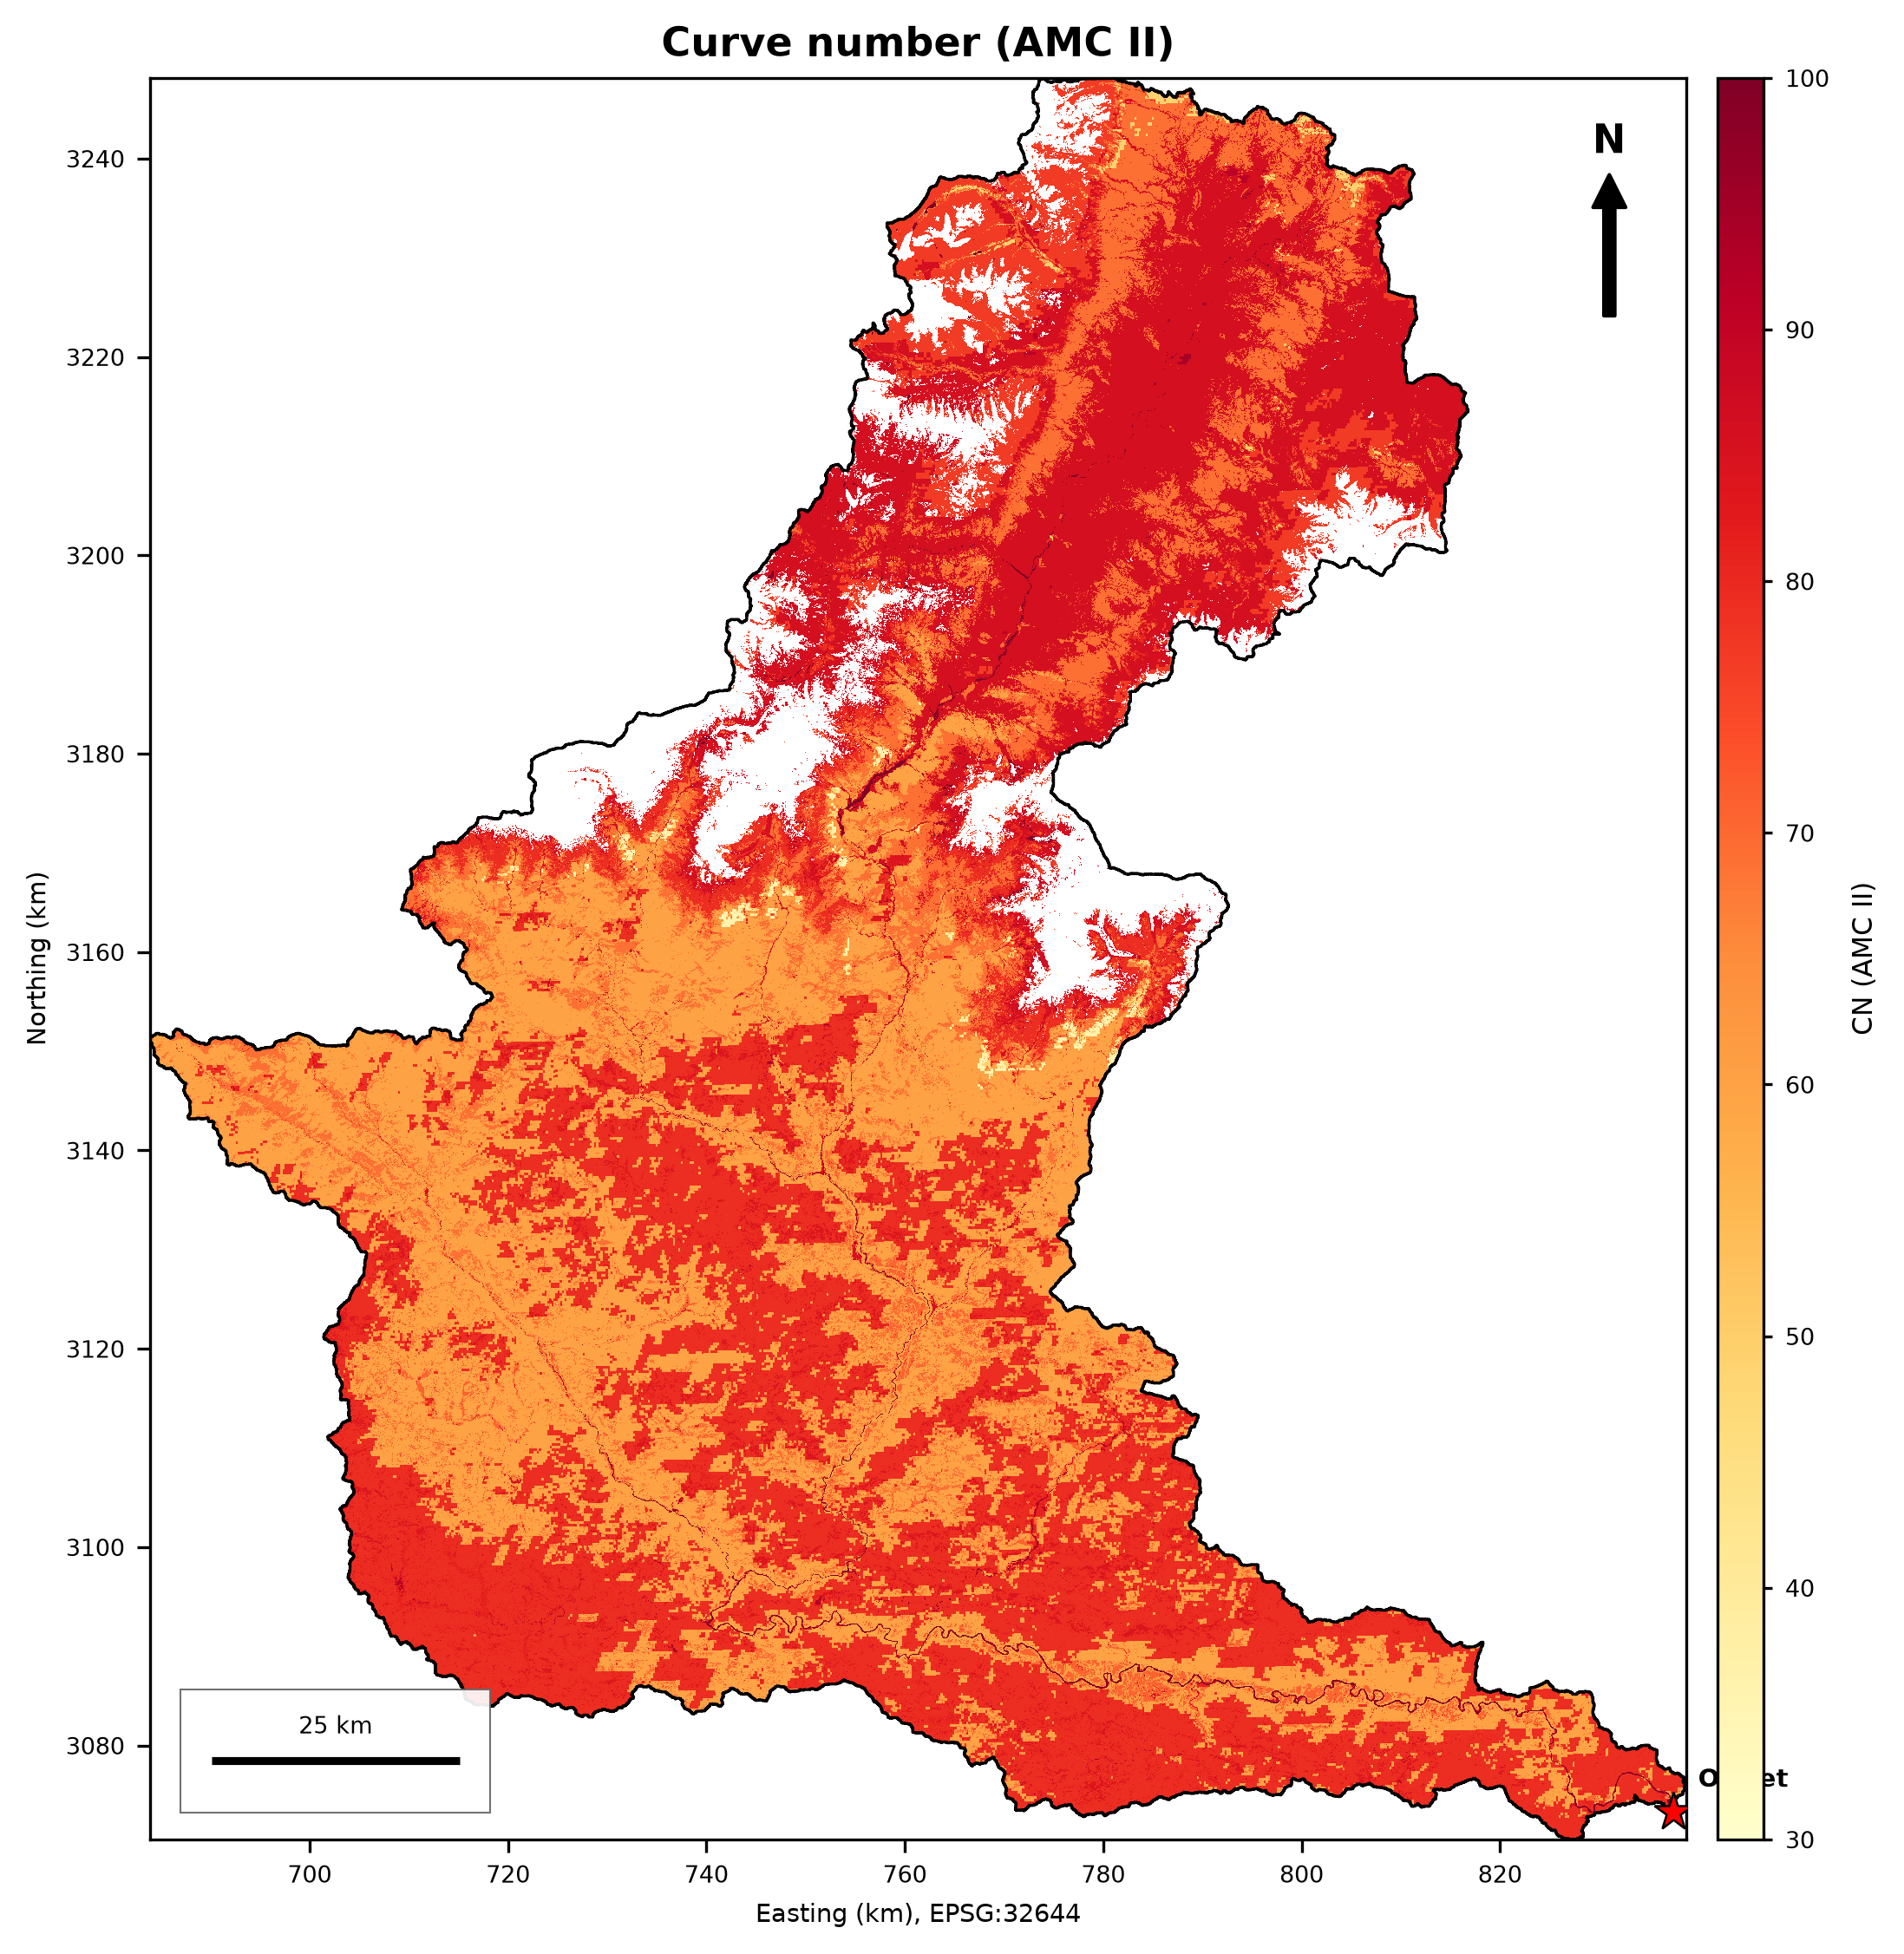

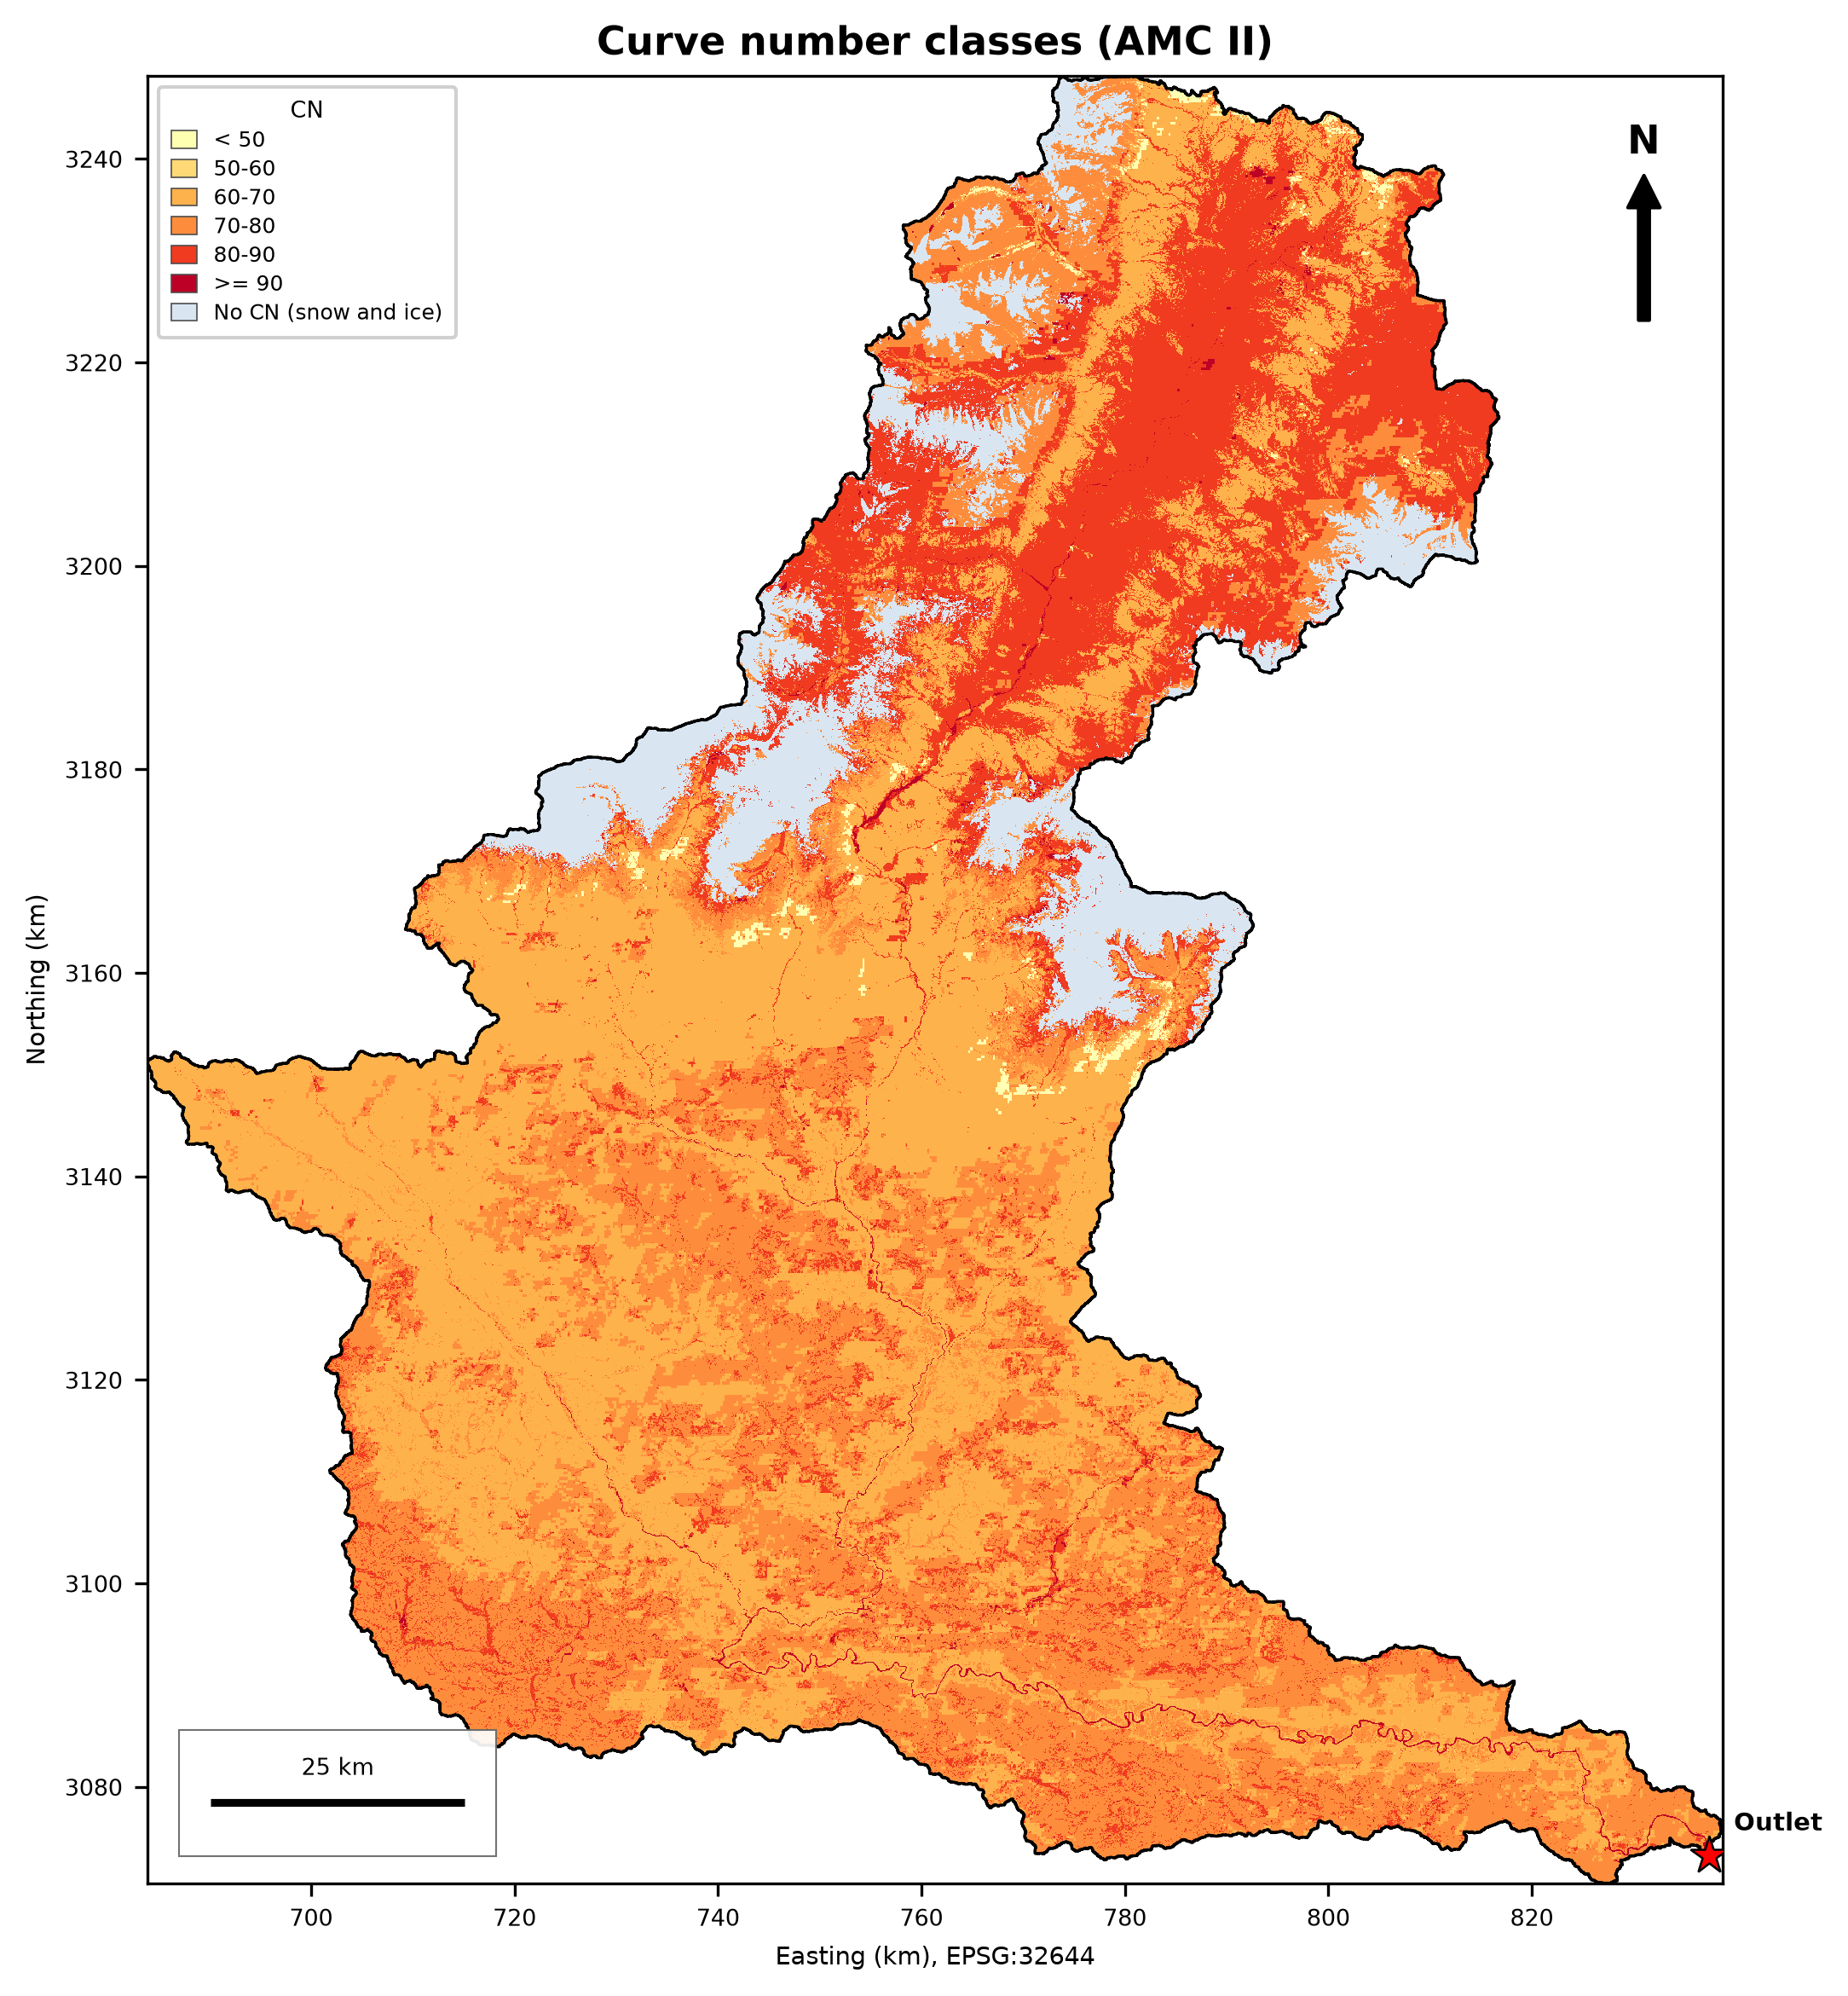

,class_id,class,cells,area_km2,percent
0,1,< 50,77900,67.85,0.57
1,2,50-60,3716,3.24,0.03
2,3,60-70,5388315,4693.23,39.53
3,4,70-80,4253285,3704.62,31.20
4,5,80-90,2727263,2375.45,20.01
5,6,>= 90,87782,76.46,0.64
6,7,No CN (snow and ice),1093274,952.24,8.02


CN class polygons done (2 s)

Basin CN (AMC II, snow/ice excluded): 73.0 | snow/ice: 8.0 % of the basin
Units flagged cn_caution (snow/ice >= 25 %): [22, 28, 29]
Highest CN: [[12.0, 85.916], [20.0, 83.399], [25.0, 82.502]]
Lowest CN : [[13.0, 63.403], [34.0, 63.976], [8.0, 65.243]]


,sub_id,area_km2,snow_ice_pct,CN_II,CN_II_incl_snow,CN_II_slopeadj,CN_I,CN_III,S_mm,Ia_mm,cn_caution
0,1,596.993,0.000,72.456,72.456,76.376,52.491,85.816,96.557,19.311,False
1,2,152.342,0.000,74.161,74.161,77.634,54.658,86.844,88.499,17.700,False
2,3,430.579,0.000,73.310,73.310,77.118,53.567,86.334,92.474,18.495,False
3,4,32.171,0.000,68.538,68.538,73.198,47.779,83.362,116.599,23.320,False
4,5,54.769,0.000,70.526,70.526,74.796,50.124,84.623,106.153,21.231,False
5,6,524.474,0.000,70.643,70.643,75.026,50.265,84.697,105.555,21.111,False
6,7,268.653,0.000,72.026,72.026,76.208,51.955,85.553,98.651,19.730,False
7,8,241.049,0.000,65.243,65.243,70.332,44.084,81.194,135.315,27.063,False
8,9,853.967,10.941,75.440,78.127,79.180,56.334,87.600,82.692,16.538,False
9,10,367.957,4.318,81.785,82.572,84.683,65.348,91.172,56.569,11.314,False


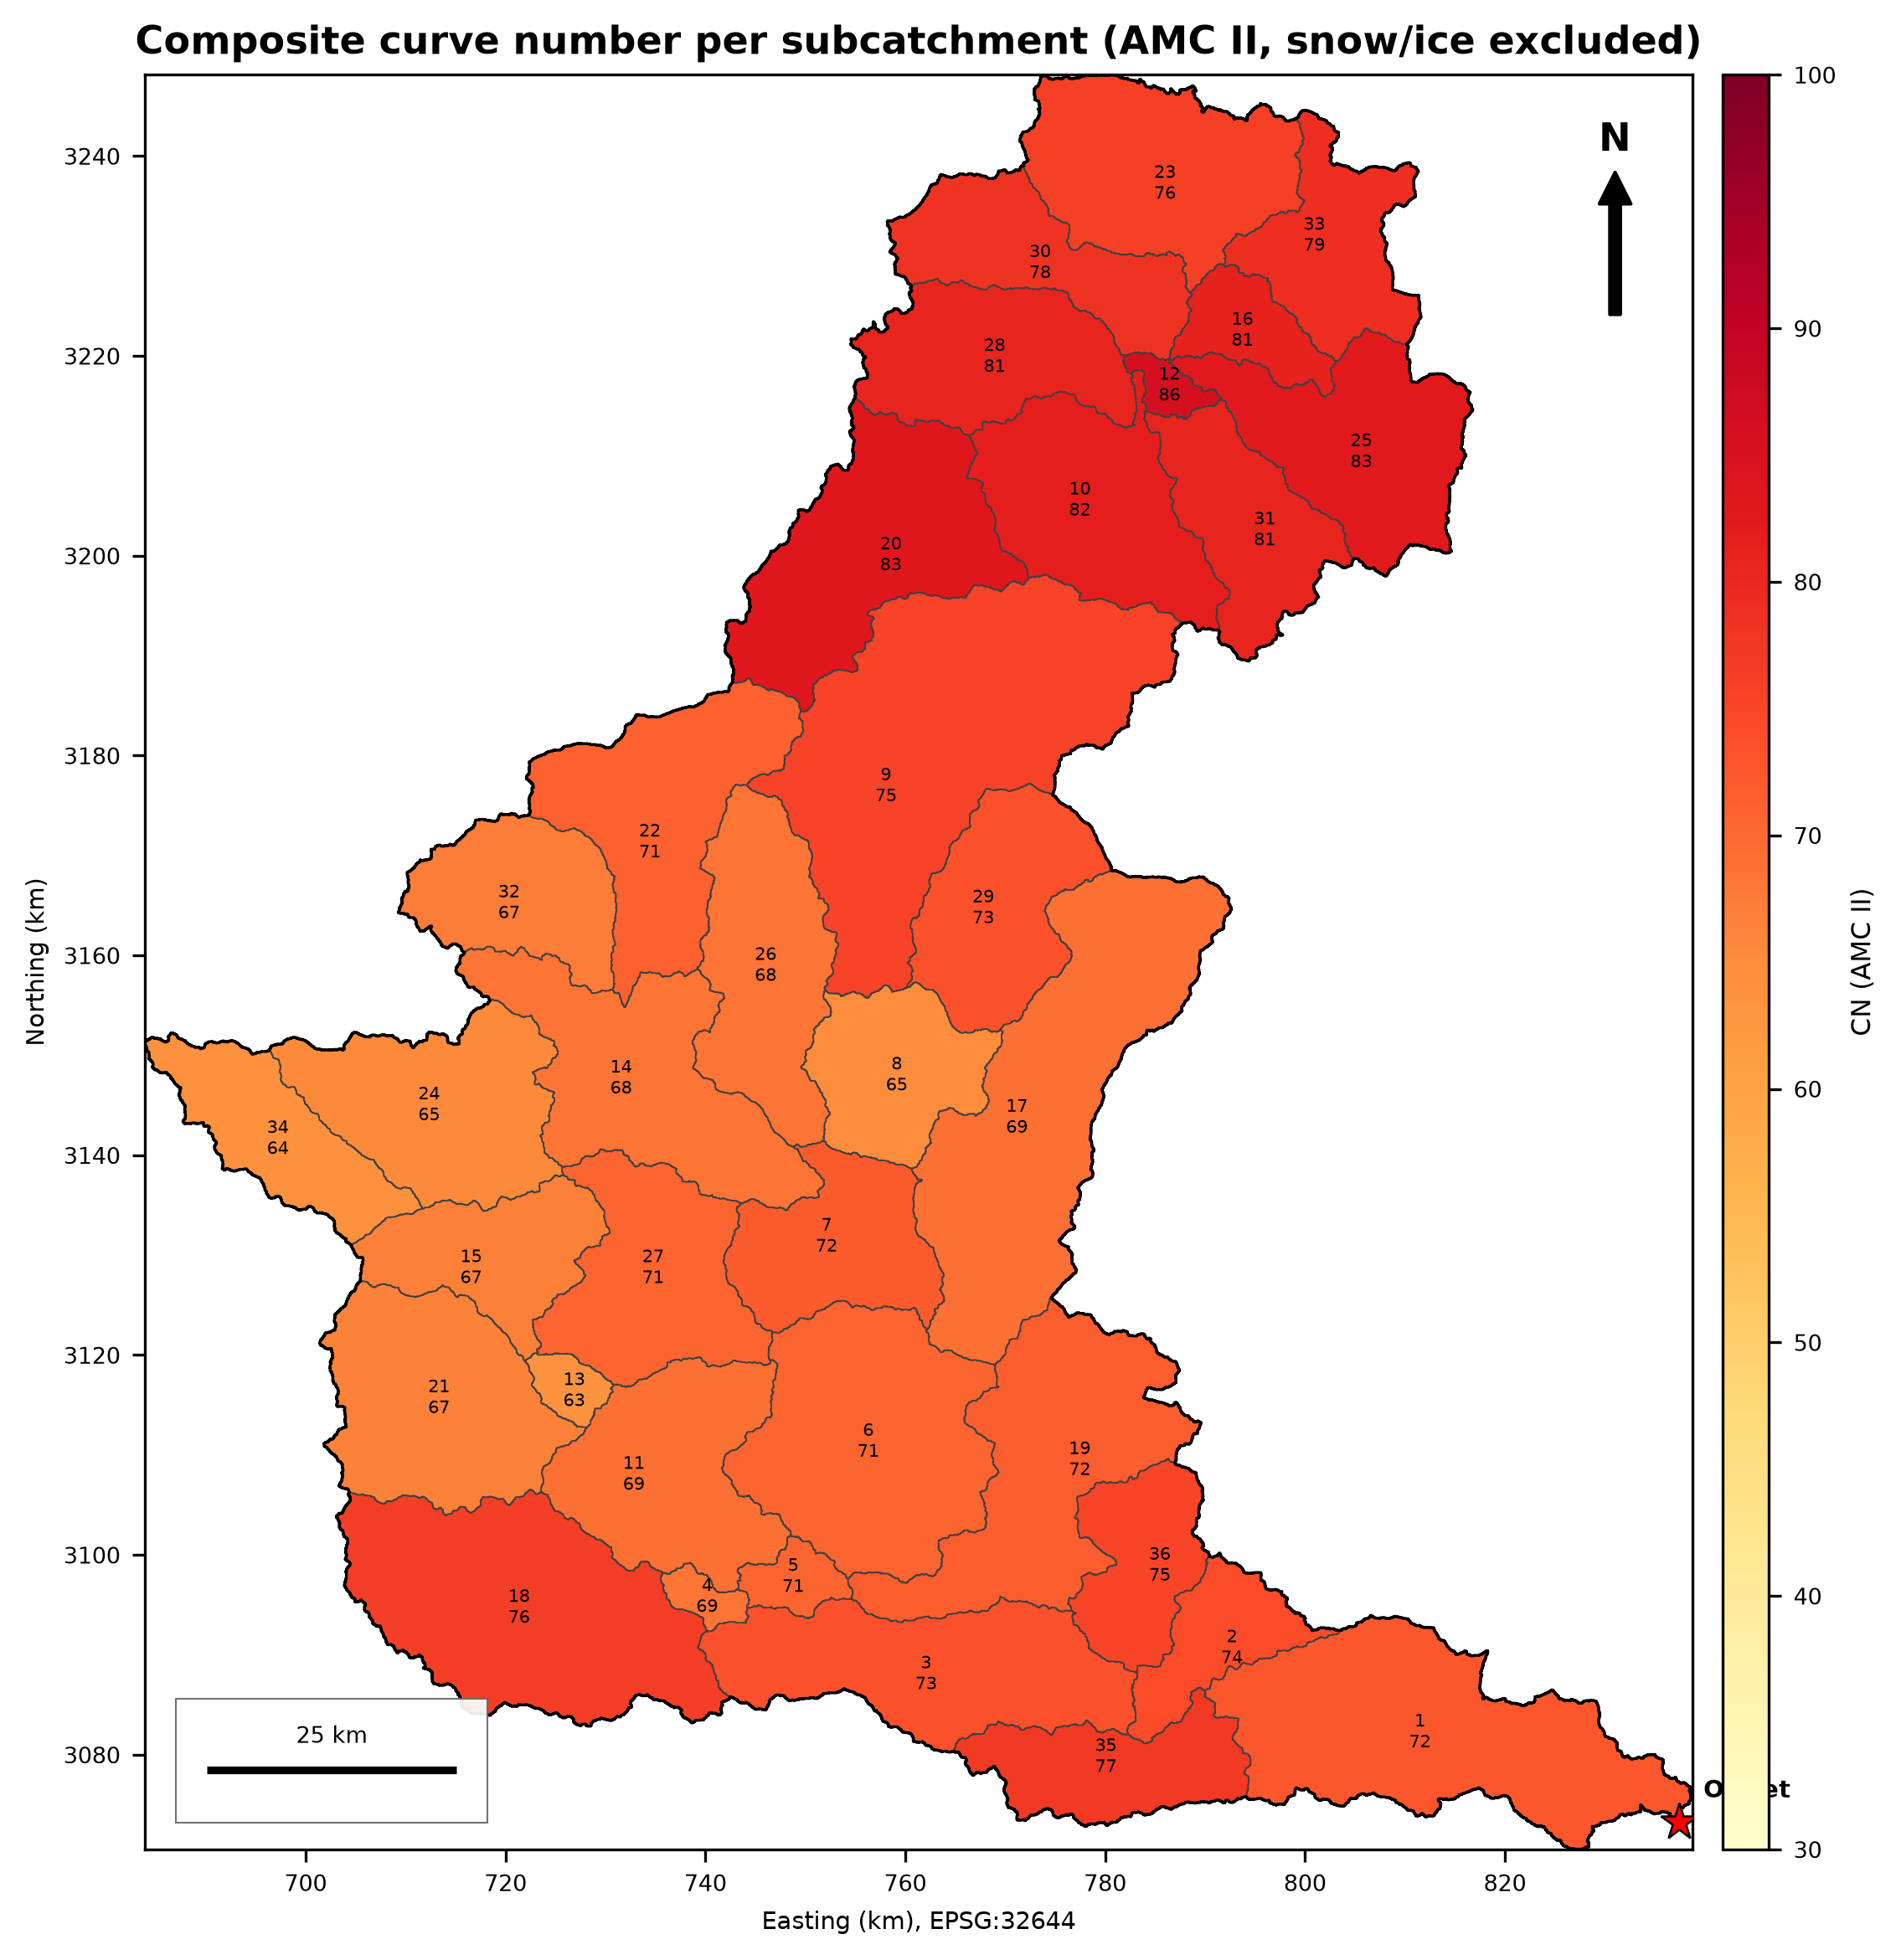

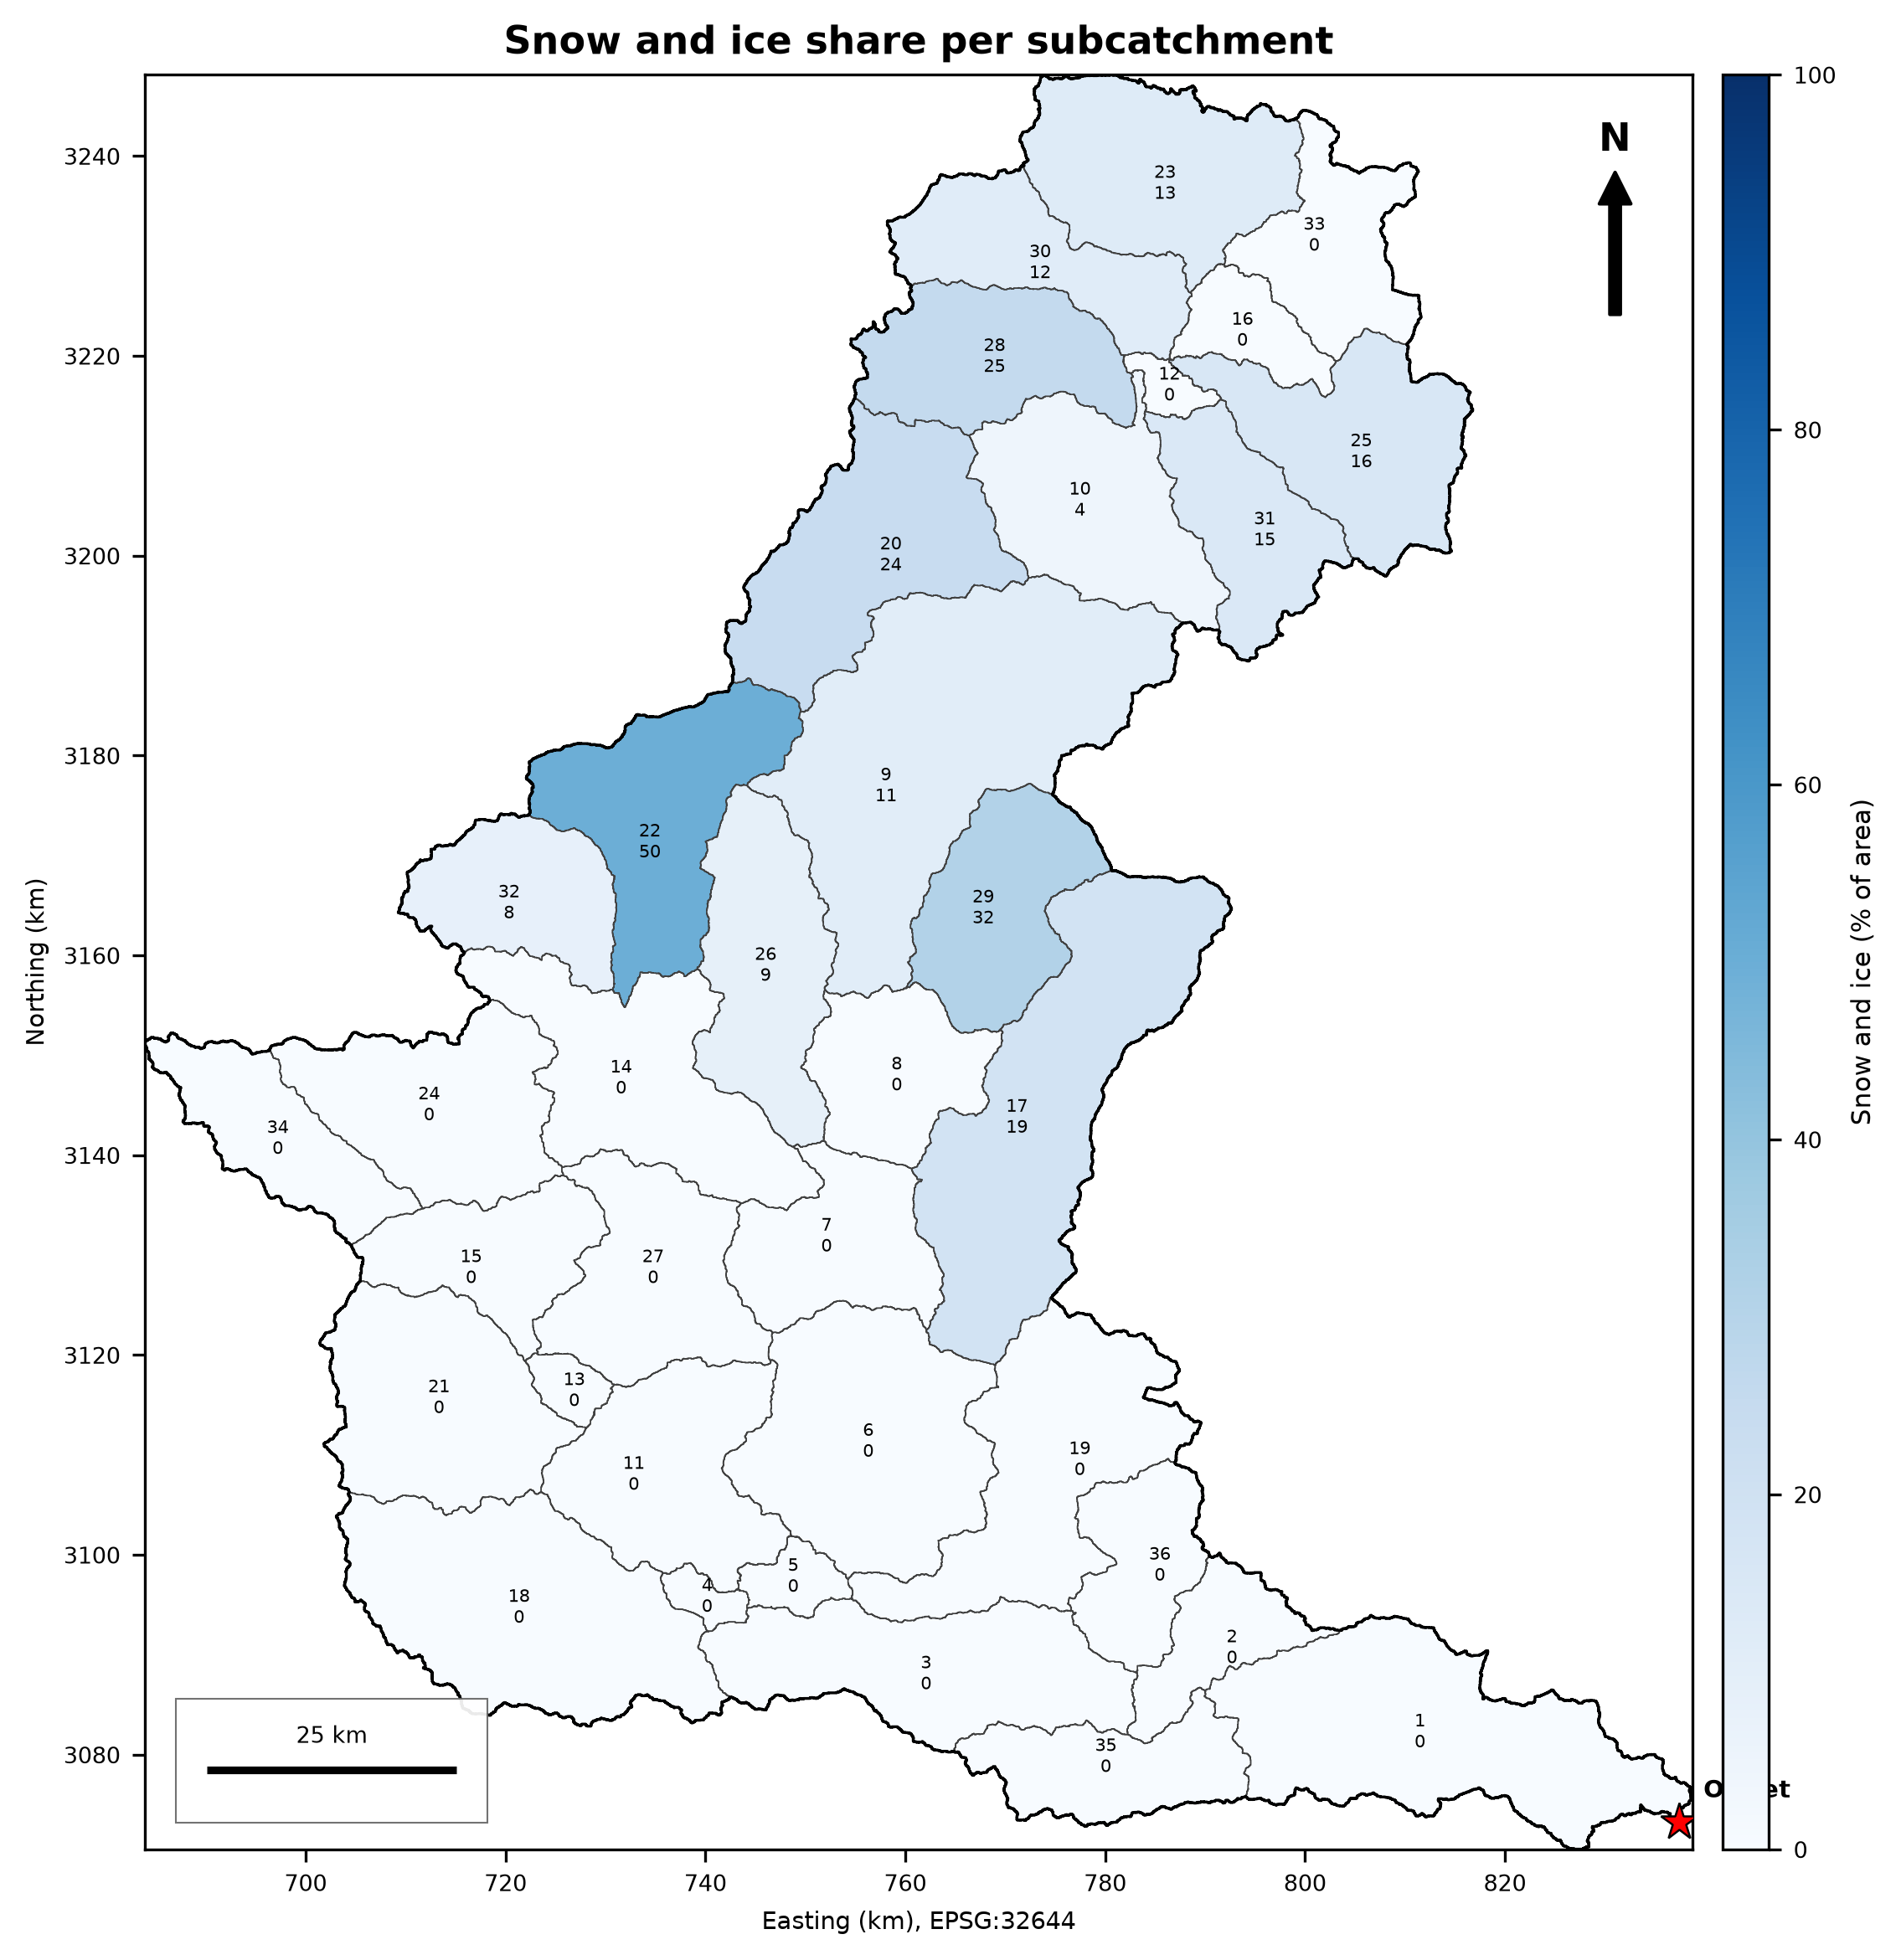

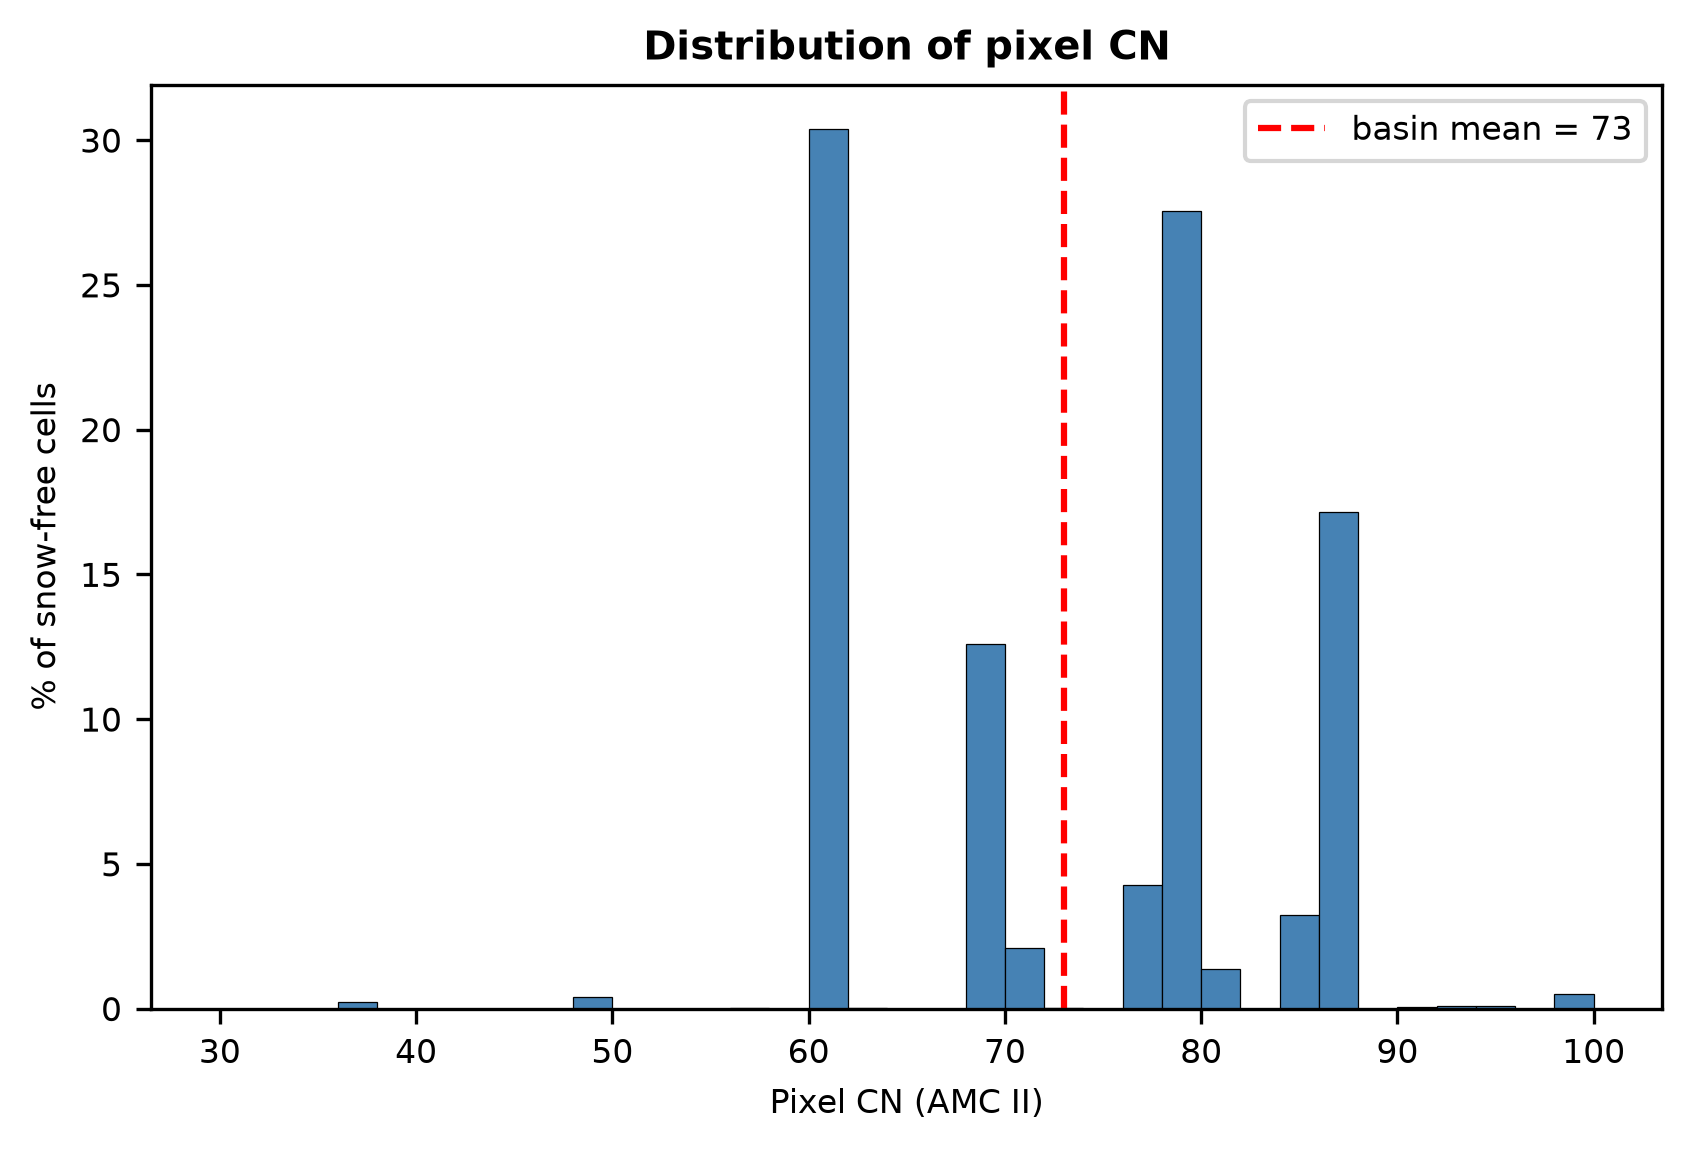

In [4]:
# ============================================================
# Cell 4: curve number - land cover x soil group, pixel and subcatchment
# ============================================================
SNOW_ICE_CN_FOR_RASTER = None     # None: snow/ice cells get no CN | 100: treat as impervious in the raster
SNOW_ICE_CN_ALT = 100             # snow/ice value used for the alternative composite CN_II_incl_snow
CN_BREAKS = [50, 60, 70, 80, 90]
CN_LABELS = ["< 50", "50-60", "60-70", "70-80", "80-90", ">= 90"]
CN_COLORS = ["#ffffb2", "#fed976", "#feb24c", "#fd8d3c", "#f03b20", "#bd0026"]

# ---------- editable CN lookup (AMC II; kept if it already exists) ----------
CN_LOOKUP = P.INPUTS / "cn_lookup.csv"
rows = [(10, "Tree cover", 36, 60, 73, 79, "woods, fair condition"),
        (20, "Shrubland", 35, 56, 70, 77, "brush, fair condition"),
        (30, "Grassland", 49, 69, 79, 84, "pasture / range, fair condition"),
        (40, "Cropland", 62, 71, 78, 81, "row crops, terraced and contoured, good"),
        (50, "Built-up", 77, 85, 90, 92, "residential, about 65 % impervious"),
        (60, "Bare / sparse vegetation", 77, 86, 91, 94, "fallow bare soil; conservative for rock and scree"),
        (70, "Snow and ice", None, None, None, None, "no CN: see SNOW_ICE_CN_FOR_RASTER / SNOW_ICE_CN_ALT"),
        (80, "Permanent water", 100, 100, 100, 100, "no infiltration"),
        (90, "Herbaceous wetland", 78, 84, 88, 90, "approximate, saturated soils"),
        (95, "Mangroves", 78, 84, 88, 90, "not expected in this basin"),
        (100, "Moss and lichen", 68, 79, 86, 89, "alpine tundra, poor-condition pasture")]
if CN_LOOKUP.exists():
    print("cn_lookup.csv already exists - keeping your version (delete it to regenerate the defaults)")
else:
    pd.DataFrame(rows, columns=["code", "class", "cn_A", "cn_B", "cn_C", "cn_D", "note"]).to_csv(CN_LOOKUP, index=False)
lk = pd.read_csv(CN_LOOKUP)
display(lk)
cn_lut = np.full((256, 5), np.nan, dtype="float32")
for _, r in lk.iterrows():
    vals = [r.cn_A, r.cn_B, r.cn_C, r.cn_D]
    if all(pd.notna(v) for v in vals):
        cn_lut[int(r.code), 1:] = vals

# ---------- inputs ----------
lc = np.nan_to_num(read_grid(P.RAS / "landcover_worldcover.tif"), nan=0).astype("uint8")
hsg = np.nan_to_num(read_grid(P.RAS / "hsg.tif"), nan=0).astype("uint8")
slope = read_grid(P.RAS / "slope_deg.tif")
assert lc.shape == hsg.shape == slope.shape == (H, W), "rasters on different grids - rerun notebooks 01-04 and Cells 2-3"

# ---------- 1) pixel CN ----------
no_soil = ws.mask & (hsg == 0) & (lc != 70)
print(f"Cells without a soil group (set to D as the conservative fallback): {int(no_soil.sum()):,}")
cn_base = cn_lut[lc, np.where(hsg == 0, 4, hsg)]
snow = (lc == 70) & ws.mask
unmapped = ws.mask & ~snow & np.isnan(cn_base)
print(f"Cells without a CN: snow/ice {int(snow.sum()):,} (excluded by design) | other {int(unmapped.sum()):,} (expect 0)")
cn_pix = cn_base.copy()
if SNOW_ICE_CN_FOR_RASTER is not None:
    cn_pix[snow] = SNOW_ICE_CN_FOR_RASTER
cn_pix[~ws.mask] = np.nan
ws.save(cn_pix, P.RAS / "curve_number_amcII.tif")

cn_idx = classify(cn_pix, CN_BREAKS)
if SNOW_ICE_CN_FOR_RASTER is None:
    cn_idx[snow] = 7
ws.save(cn_idx, P.RAS / "cn_classes.tif", nodata=0, dtype="uint8")
CN_LABELS_ALL = CN_LABELS + ["No CN (snow and ice)"]
cls_list = [(i + 1, CN_LABELS[i], CN_COLORS[i]) for i in range(6)]
if (cn_idx == 7).any():
    cls_list.append((7, CN_LABELS_ALL[6], "#d9e6f2"))

make_map(cn_pix, ws, P.FIG / "05_curve_number.png", title="Curve number (AMC II)",
         label="CN (AMC II)", cmap="YlOrRd", vmin=30, vmax=100)
make_map(cn_idx, ws, P.FIG / "05_cn_classes.png", title="Curve number classes (AMC II)",
         label="CN", classes=cls_list)
tab_cn = pd.DataFrame([(i, CN_LABELS_ALL[i - 1], int((cn_idx == i).sum())) for i in range(1, 8) if (cn_idx == i).any()],
                      columns=["class_id", "class", "cells"])
tab_cn["area_km2"] = (tab_cn.cells * ws.cell_area_km2).round(2)
tab_cn["percent"] = (100 * tab_cn.cells / ws.n_cells).round(2)
save_table(tab_cn, P.TAB / "05_cn_classes.csv"); display(tab_cn)
t0 = time.time()
classes_to_vector(cn_idx, ws, CN_LABELS_ALL, P.VEC / "cn_classes", sieve_px=300)
print(f"CN class polygons done ({time.time() - t0:.0f} s)")

# ---------- 2) composites per subcatchment ----------
valid = np.isfinite(cn_base) & ws.mask                     # snow-free cells with a CN

def wmean(vals, mask):
    s = np.bincount(sub[mask], weights=vals[mask].astype("float64"), minlength=N_SUB + 1)[1:]
    n = np.bincount(sub[mask], minlength=N_SUB + 1)[1:]
    return np.where(n > 0, s / np.maximum(n, 1), np.nan), n

cn_excl, n_valid = wmean(cn_base, valid)
cn_incl, _ = wmean(np.where(snow, SNOW_ICE_CN_ALT, cn_base), valid | snow)
slp = np.tan(np.deg2rad(np.nan_to_num(slope, nan=0)))
cn3 = 23 * cn_base / (10 + 0.13 * cn_base)
cn_sa = np.minimum((cn3 - cn_base) / 3 * (1 - 2 * np.exp(-13.86 * slp)) + cn_base, 100)   # Sharpley-Williams
cn_sa_sub, _ = wmean(cn_sa, valid)
del cn3, cn_sa, slp

cn_df = pd.DataFrame({"sub_id": np.arange(1, N_SUB + 1), "area_km2": A_SUB,
                      "snow_ice_pct": 100 * np.bincount(sub[snow], minlength=N_SUB + 1)[1:] / CELLS_SUB,
                      "CN_II": cn_excl, "CN_II_incl_snow": cn_incl, "CN_II_slopeadj": cn_sa_sub})
cn_df["CN_I"] = 4.2 * cn_df.CN_II / (10 - 0.058 * cn_df.CN_II)
cn_df["CN_III"] = 23 * cn_df.CN_II / (10 + 0.13 * cn_df.CN_II)
cn_df["S_mm"] = 25400 / cn_df.CN_II - 254                # potential maximum retention
cn_df["Ia_mm"] = 0.2 * cn_df.S_mm                        # initial abstraction
cn_df["cn_caution"] = cn_df.snow_ice_pct >= 25           # CN describes little of these units
cn_df = cn_df.round(3)
save_table(cn_df, P.TAB / "05_curve_number_by_subcatchment.csv")

basin_cn = float(np.nansum(cn_excl * n_valid) / n_valid.sum())
print(f"\nBasin CN (AMC II, snow/ice excluded): {basin_cn:.1f} | snow/ice: {100 * snow.sum() / ws.n_cells:.1f} % of the basin")
print(f"Units flagged cn_caution (snow/ice >= 25 %): {cn_df.loc[cn_df.cn_caution, 'sub_id'].tolist()}")
print(f"Highest CN: {cn_df.nlargest(3, 'CN_II')[['sub_id', 'CN_II']].values.tolist()}")
print(f"Lowest CN : {cn_df.nsmallest(3, 'CN_II')[['sub_id', 'CN_II']].values.tolist()}")
display(cn_df)

# ---------- 3) maps, histogram, vectors ----------
add_to_gsub(cn_df, ["CN_II", "CN_II_incl_snow", "CN_II_slopeadj", "CN_I", "CN_III", "S_mm", "Ia_mm", "snow_ice_pct"])
choropleth("CN_II", "05_cn_by_subcatchment.png", "Composite curve number per subcatchment (AMC II, snow/ice excluded)",
           "CN (AMC II)", vmin=30, vmax=100)
choropleth("snow_ice_pct", "05_snow_ice_by_subcatchment.png", "Snow and ice share per subcatchment",
           "Snow and ice (% of area)", cmap="Blues", vmin=0, vmax=100)

cnts, edges = np.histogram(cn_base[valid], bins=np.arange(30, 102, 2))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(edges[:-1], 100 * cnts / cnts.sum(), width=2, align="edge", color="steelblue", edgecolor="k", linewidth=0.3)
ax.axvline(basin_cn, color="red", ls="--", label=f"basin mean = {basin_cn:.0f}")
ax.set_xlabel("Pixel CN (AMC II)"); ax.set_ylabel("% of snow-free cells"); ax.legend()
ax.set_title("Distribution of pixel CN", fontweight="bold")
fig.savefig(P.FIG / "05_cn_histogram.png", dpi=250, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

gsub.to_file(P.VEC / "curve_number_subcatchments.gpkg", driver="GPKG")
short = gsub[["sub_id", "down_id", "area_km2", "CN_II", "CN_I", "CN_III", "S_mm", "Ia_mm", "snow_ice_pct", "geometry"]]
short.rename(columns={"snow_ice_pct": "snow_pct"}).to_file(P.VEC / "curve_number_subcatchments.shp")
del cn_base, cn_pix, cn_idx, valid, snow

In [5]:
# ============================================================
# Cell 5: runoff-parameter table per subcatchment
# ============================================================
lc_sub   = pd.read_csv(P.TAB / "05_subcatchment_landcover.csv")
soil_sub = pd.read_csv(P.TAB / "05_subcatchment_soil.csv")
cn_df    = pd.read_csv(P.TAB / "05_curve_number_by_subcatchment.csv")

master = (sub_info.merge(lc_sub, on="sub_id").merge(soil_sub, on="sub_id")
          .merge(cn_df.drop(columns=["area_km2"]), on="sub_id"))

# ---------- travel-time estimates (empirical; calibrated on small catchments, use as order of magnitude) ----------
L_m = master.flowpath_length_km * 1000
grad = master.flowpath_gradient_m_per_m.clip(lower=1e-4)
master["tc_kirpich_h"] = 0.0195 * L_m ** 0.77 * grad ** -0.385 / 60
Y_pct = 100 * np.tan(np.deg2rad(master.slope_mean_deg))
master["tlag_scs_h"] = ((master.flowpath_length_km * 3280.84) ** 0.8 * (master.S_mm / 25.4 + 1) ** 0.7
                        / (1900 * Y_pct ** 0.5))
master["tc_scs_h"] = master.tlag_scs_h / 0.6

first = ["sub_id", "down_id", "on_main_stem", "area_km2", "upstr_area_km2", "CN_II", "CN_II_incl_snow",
         "CN_II_slopeadj", "CN_I", "CN_III", "S_mm", "Ia_mm", "snow_ice_pct", "cn_caution",
         "dominant_landcover", "dominant_hsg", "dominant_texture", "tc_kirpich_h", "tlag_scs_h", "tc_scs_h"]
master = master[first + [c for c in master.columns if c not in first]].round(3)
assert master.sub_id.is_unique and len(master) == N_SUB
print(f"Rows: {len(master)} | columns: {master.shape[1]} | area {master.area_km2.sum():,.1f} km2 "
      f"| units without a CN: {int(master.CN_II.isna().sum())}")
save_table(master, P.TAB / "05_subcatchment_runoff_parameters.csv")

gfull = gpd.GeoDataFrame(master, geometry=gsub.set_index("sub_id").loc[master.sub_id].geometry.values, crs=ws.crs)
gfull.to_file(P.VEC / "subcatchment_runoff_parameters.gpkg", driver="GPKG")

guide = pd.DataFrame([
    ("CN_II", "composite curve number, AMC II, area-weighted, snow and ice excluded"),
    ("CN_II_incl_snow", "same, with snow and ice counted as CN 100"),
    ("CN_II_slopeadj", "same as CN_II after the Sharpley-Williams steep-slope adjustment (optional)"),
    ("CN_I / CN_III", "dry / wet antecedent conditions, converted from CN_II"),
    ("S_mm / Ia_mm", "potential maximum retention (25400/CN - 254) and initial abstraction (0.2 S)"),
    ("snow_ice_pct / cn_caution", "share of snow and ice; cn_caution is True at 25 % or more"),
    ("lc_*_pct", "land cover shares (ESA WorldCover 2021)"),
    ("hsg_A_pct ... hsg_D_pct", "hydrologic soil group shares (SoilGrids 2.0 texture)"),
    ("tc_kirpich_h", "Kirpich time of concentration from the in-unit longest flowpath (hours)"),
    ("tlag_scs_h / tc_scs_h", "SCS lag, and time of concentration = lag / 0.6 (hours)")],
    columns=["column", "meaning"])
save_table(guide, P.TAB / "05_runoff_parameters_columns.csv")

display(master[["sub_id", "down_id", "area_km2", "CN_II", "CN_II_incl_snow", "snow_ice_pct", "S_mm", "Ia_mm",
                "tc_kirpich_h", "tc_scs_h", "cn_caution"]].round(2))
print("Note: Kirpich and SCS lag were calibrated on small catchments; for units of hundreds of km2 "
      "treat them as order-of-magnitude only.")

Rows: 36 | columns: 75 | area 11,873.1 km2 | units without a CN: 0


,sub_id,down_id,area_km2,CN_II,CN_II_incl_snow,snow_ice_pct,S_mm,Ia_mm,tc_kirpich_h,tc_scs_h,cn_caution
0,1,0,596.99,72.46,72.46,0.00,96.56,19.31,12.63,8.53,False
1,2,1,152.34,74.16,74.16,0.00,88.50,17.70,2.47,3.19,False
2,3,2,430.58,73.31,73.31,0.00,92.47,18.50,9.11,7.80,False
3,4,3,32.17,68.54,68.54,0.00,116.60,23.32,0.90,1.59,False
4,5,4,54.77,70.53,70.53,0.00,106.15,21.23,1.41,2.27,False
5,6,5,524.47,70.64,70.64,0.00,105.56,21.11,4.72,5.63,False
6,7,6,268.65,72.03,72.03,0.00,98.65,19.73,2.58,3.91,False
7,8,7,241.05,65.24,65.24,0.00,135.32,27.06,2.32,4.60,False
8,9,8,853.97,75.44,78.13,10.94,82.69,16.54,5.61,6.64,False
9,10,9,367.96,81.78,82.57,4.32,56.57,11.31,2.57,3.19,False


Note: Kirpich and SCS lag were calibrated on small catchments; for units of hundreds of km2 treat them as order-of-magnitude only.


In [6]:
# ============================================================
# Cell 6: output inventory
# ============================================================
expected = {
    P.RAS: ["landcover_worldcover.tif", "soil_texture.tif", "hsg.tif", "soil_sand_pct.tif", "soil_clay_pct.tif",
            "curve_number_amcII.tif", "cn_classes.tif"],
    P.VEC: ["landcover.gpkg", "hsg.gpkg", "soil_texture.gpkg", "cn_classes.gpkg",
            "curve_number_subcatchments.gpkg", "curve_number_subcatchments.shp",
            "subcatchment_runoff_parameters.gpkg"]}
print(f"{'file':<42}{'exists':<8}{'MB':>8}")
for folder, names in expected.items():
    for n in names:
        p = folder / n
        print(f"{n:<42}{str(p.exists()):<8}{(p.stat().st_size / 1e6 if p.exists() else 0):>8.1f}")
for folder in (P.FIG, P.TAB):
    for p in sorted(folder.glob("05_*")):
        print(f"{p.name:<42}{'True':<8}{p.stat().st_size / 1e6:>8.2f}")
print(f"\nSoil download cache: {sum(f.stat().st_size for f in SOIL_DIR.glob('*.tif')) / 1e6:.1f} MB in {SOIL_DIR.name}")

file                                      exists        MB
landcover_worldcover.tif                  True         1.3
soil_texture.tif                          True         0.5
hsg.tif                                   True         0.5
soil_sand_pct.tif                         True        13.3
soil_clay_pct.tif                         True        13.2
curve_number_amcII.tif                    True         3.1
cn_classes.tif                            True         1.2
landcover.gpkg                            True         9.2
hsg.gpkg                                  True         1.7
soil_texture.gpkg                         True         1.7
cn_classes.gpkg                           True        10.3
curve_number_subcatchments.gpkg           True         1.5
curve_number_subcatchments.shp            True         1.4
subcatchment_runoff_parameters.gpkg       True         1.6
05_cn_by_subcatchment.png                 True        0.43
05_cn_classes.png                         True        0.